In [ ]:
import os
import zipfile
from pathlib import Path
from collections import Counter

zip_files = [
    "/content/job54.zip",
    "/content/job62.zip"
]

image_exts = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

for zip_path in zip_files:
    print("\n" + "=" * 65)
    print("FILE:", os.path.basename(zip_path))
    print("=" * 65)

    if not os.path.exists(zip_path):
        print("KHONG TIM THAY FILE:", zip_path)
        print("Hay kiem tra lai ten file trong bang Files cua Colab.")
        continue

    print(f"Kich thuoc ZIP: {os.path.getsize(zip_path) / (1024**2):.2f} MB")

    with zipfile.ZipFile(zip_path, "r") as z:
        files = [
            name for name in z.namelist()
            if not name.endswith("/")
        ]

        images = [
            name for name in files
            if Path(name).suffix.lower() in image_exts
        ]

        txt_files = [
            name for name in files
            if Path(name).suffix.lower() == ".txt"
        ]

        yaml_files = [
            name for name in files
            if Path(name).suffix.lower() in {".yaml", ".yml"}
        ]

        print("Tong so file trong ZIP:", len(files))
        print("So file anh:", len(images))
        print("So file TXT:", len(txt_files))
        print("So file YAML:", len(yaml_files))

        print("\n--- Mot so duong dan dau tien ---")
        for name in files[:20]:
            print(name)

        print("\n--- File YAML va noi dung ---")
        if yaml_files:
            for name in yaml_files[:5]:
                print(f"\n[{name}]")
                print(z.read(name).decode("utf-8-sig", errors="replace")[:4000])
        else:
            print("Khong tim thay file YAML.")

        print("\n--- Vi du annotation TXT ---")
        label_candidates = [
            name for name in txt_files
            if "label" in name.lower()
            or "obj_train_data" in name.lower()
            or "obj_valid_data" in name.lower()
        ]

        if not label_candidates:
            label_candidates = txt_files

        shown = 0
        for name in label_candidates:
            content = z.read(name).decode("utf-8-sig", errors="replace").strip()
            if content:
                print(f"\n[{name}]")
                print("\n".join(content.splitlines()[:2]))
                shown += 1
            if shown >= 3:
                break

        if shown == 0:
            print("Khong tim thay annotation TXT co noi dung.")


FILE: job54.zip
Kich thuoc ZIP: 110.10 MB
Tong so file trong ZIP: 595
So file anh: 297
So file TXT: 297
So file YAML: 1

--- Mot so duong dan dau tien ---
train.txt
data.yaml
labels/train/batch_004/NhatTan__layout_20260908_142002__000920.txt
labels/train/batch_004/NhatTan__layout_20260908_142002__001230.txt
labels/train/batch_004/NhatTan__layout_20260908_142002__000740.txt
labels/train/batch_004/BaoAnh__screen_on_off_outdoor_pm_20260908_131056__000220.txt
labels/train/batch_004/NhatTan__layout_20260908_142209__001250.txt
labels/train/batch_004/NhatTan__crowd_20260908_143116__000420.txt
labels/train/batch_004/NhatTan__crowd_20260908_143116__000430.txt
labels/train/batch_004/NhatTan__layout_20260908_142002__001050.txt
labels/train/batch_004/NhatTan__crowd_20260908_143116__000170.txt
labels/train/batch_004/NhatTan__layout_20260908_142209__001380.txt
labels/train/batch_004/BaoAnh__screen_on_off_outdoor_pm_20260908_130620__000430.txt
labels/train/batch_004/NhatTan__layout_20260908_142002__

In [ ]:
import os
import zipfile
from pathlib import Path
from collections import Counter
import yaml

ZIP_FILES = [
    "/content/job54.zip",
    "/content/job62.zip"
]

IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
results = {}

for zip_path in ZIP_FILES:
    print("\n" + "=" * 60)
    print("DATASET:", os.path.basename(zip_path))
    print("=" * 60)

    if not os.path.exists(zip_path):
        print("KHONG TIM THAY FILE:", zip_path)
        continue

    with zipfile.ZipFile(zip_path) as z:
        files = [
            n for n in z.namelist()
            if not n.endswith("/")
        ]

        images = [
            n for n in files
            if Path(n).suffix.lower() in IMAGE_EXTS
        ]

        labels = [
            n for n in files
            if Path(n).suffix.lower() == ".txt"
            and (
                n.startswith("labels/")
                or "/labels/" in n
            )
        ]

        yaml_files = [
            n for n in files
            if Path(n).name.lower() in {"data.yaml", "data.yml"}
        ]

        print("Dung luong ZIP: %.2f MB" %
              (os.path.getsize(zip_path) / 1024**2))
        print("So anh:", len(images))
        print("So file label:", len(labels))

        # Doc cau hinh class
        names = {}
        if yaml_files:
            yaml_name = yaml_files[0]
            config = yaml.safe_load(
                z.read(yaml_name).decode("utf-8-sig")
            )
            print("\nFile YAML:", yaml_name)
            print("Train:", config.get("train"))
            print("Names:", config.get("names"))

            raw_names = config.get("names", {})
            if isinstance(raw_names, dict):
                names = {int(k): str(v) for k, v in raw_names.items()}
            elif isinstance(raw_names, list):
                names = dict(enumerate(raw_names))
        else:
            print("CANH BAO: Khong tim thay data.yaml")

        # Kiem tra class va cau truc polygon
        class_objects = Counter()
        format_counts = Counter()
        invalid_lines = 0
        empty_labels = 0
        total_objects = 0

        label_stems = set()

        for name in labels:
            label_stems.add(Path(name).stem)
            content = z.read(name).decode(
                "utf-8-sig", errors="replace"
            ).strip()

            if not content:
                empty_labels += 1
                continue

            for line in content.splitlines():
                parts = line.split()

                try:
                    cls = int(parts[0])
                    coords = [float(x) for x in parts[1:]]
                except (ValueError, IndexError):
                    invalid_lines += 1
                    continue

                if len(parts) == 5:
                    format_counts["detection_box"] += 1
                elif len(coords) >= 6 and len(coords) % 2 == 0:
                    format_counts["polygon_segmentation"] += 1
                else:
                    format_counts["invalid_format"] += 1
                    invalid_lines += 1
                    continue

                if not all(0 <= x <= 1 for x in coords):
                    invalid_lines += 1

                class_objects[cls] += 1
                total_objects += 1

        image_stems = {Path(n).stem for n in images}

        print("\nTong so instance:", total_objects)
        print("So instance theo class ID:", dict(sorted(class_objects.items())))
        print("So instance theo dinh dang:", dict(format_counts))
        print("So file label rong:", empty_labels)
        print("So dong can kiem tra:", invalid_lines)

        print("\nSo ten anh co label trung stem:",
              len(image_stems & label_stems))
        print("Anh chua co label theo stem:",
              len(image_stems - label_stems))
        print("Label chua co anh theo stem:",
              len(label_stems - image_stems))

        print("\nMot so duong dan anh:")
        for n in images[:3]:
            print(" ", n)

        # Xem manifest train.txt neu co
        manifests = [
            n for n in files
            if Path(n).name == "train.txt"
        ]
        if manifests:
            print("\nVi du train.txt:")
            lines = z.read(manifests[0]).decode(
                "utf-8-sig", errors="replace"
            ).splitlines()
            for line in lines[:3]:
                print(" ", line)

        results[os.path.basename(zip_path)] = {
            "names": names,
            "image_stems": image_stems,
            "label_stems": label_stems,
            "classes": set(class_objects),
        }

# So sanh hai dataset
if len(results) == 2:
    a = results["job54.zip"]
    b = results["job62.zip"]

    print("\n" + "=" * 60)
    print("SO SANH HAI DATASET")
    print("=" * 60)
    print("Class job54:", a["names"])
    print("Class job62:", b["names"])
    print("Ten anh trung nhau:",
          len(a["image_stems"] & b["image_stems"]))
    print("Class ID thuc te job54:", sorted(a["classes"]))
    print("Class ID thuc te job62:", sorted(b["classes"]))


DATASET: job54.zip
Dung luong ZIP: 110.10 MB
So anh: 297
So file label: 296

File YAML: data.yaml
Train: train.txt
Names: {0: 'hat', 1: 'gloves', 2: 'mask', 3: 'pants', 4: 'shoes', 5: 'long-sleeved shirt'}

Tong so instance: 4470
So instance theo class ID: {0: 1511, 1: 400, 2: 425, 3: 485, 4: 280, 5: 1369}
So instance theo dinh dang: {'polygon_segmentation': 4470}
So file label rong: 0
So dong can kiem tra: 0

So ten anh co label trung stem: 296
Anh chua co label theo stem: 1
Label chua co anh theo stem: 0

Mot so duong dan anh:
  images/train/batch_004/NhatTan__layout_20260908_142209__001580.jpg
  images/train/batch_004/NhatTan__layout_20260908_142002__001280.jpg
  images/train/batch_004/NhatTan__layout_20260908_142002__001190.jpg

Vi du train.txt:
  data/images/train/batch_004/BaoAnh__screen_on_off_20260908_113356__008810.jpg
  data/images/train/batch_004/BaoAnh__screen_on_off_20260908_113356__008820.jpg
  data/images/train/batch_004/BaoAnh__screen_on_off_20260908_113356__008830.jpg

In [ ]:
import zipfile
from pathlib import PurePosixPath

zip_files = [
    "/content/job54.zip",
    "/content/job62.zip"
]

image_exts = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

for zip_path in zip_files:
    print("\n" + "=" * 60)
    print("KIEM TRA:", PurePosixPath(zip_path).name)
    print("=" * 60)

    with zipfile.ZipFile(zip_path) as z:
        members = {
            name for name in z.namelist()
            if not name.endswith("/")
        }

        images = sorted(
            name for name in members
            if name.startswith("images/")
            and PurePosixPath(name).suffix.lower() in image_exts
        )

        labels = {
            name for name in members
            if name.startswith("labels/")
            and PurePosixPath(name).suffix.lower() == ".txt"
        }

        # Kiem tra duong dan trong train.txt
        train_lines = [
            line.strip().replace("\\", "/")
            for line in z.read("train.txt").decode(
                "utf-8-sig", errors="replace"
            ).splitlines()
            if line.strip()
        ]

        exact_matches = sum(line in members for line in train_lines)

        normalized_lines = [
            line.removeprefix("./").removeprefix("data/")
            for line in train_lines
        ]

        normalized_matches = sum(
            line in members for line in normalized_lines
        )

        print("So dong trong train.txt:", len(train_lines))
        print("Duong dan khop ZIP truc tiep:", exact_matches)
        print("Duong dan khop sau khi bo prefix data/:",
              normalized_matches)

        print("\nVi du duong dan trong train.txt:")
        for line in train_lines[:3]:
            normalized = line.removeprefix("./").removeprefix("data/")
            print("  Goc:", line)
            print("  Sau chuan hoa:", normalized)
            print("  Ton tai trong ZIP:", normalized in members)

        # Kiem tra tung anh co file label tuong ung khong
        missing_labels = []

        for img in images:
            relative = img.removeprefix("images/")
            expected_label = str(
                PurePosixPath("labels") /
                PurePosixPath(relative).with_suffix(".txt")
            )

            if expected_label not in labels:
                missing_labels.append((img, expected_label))

        print("\nSo anh khong co label tuong ung:", len(missing_labels))

        for img, label in missing_labels[:10]:
            print("  Anh:", img)
            print("  Label mong doi:", label)

        # Kiem tra label khong co anh tuong ung
        image_set = set(images)
        orphan_labels = []

        for label in sorted(labels):
            relative = label.removeprefix("labels/")
            possible_image = str(
                PurePosixPath("images") / PurePosixPath(relative)
            )

            image_stem = PurePosixPath(relative).stem

            if possible_image not in image_set:
                candidates = [
                    img for img in images
                    if PurePosixPath(img).stem == image_stem
                ]
                orphan_labels.append((label, candidates))

        print("\nSo label khong khop duong dan anh:", len(orphan_labels))

        for label, candidates in orphan_labels[:10]:
            print("  Label:", label)
            print("  Anh cung ten:", candidates[:3])


KIEM TRA: job54.zip
So dong trong train.txt: 297
Duong dan khop ZIP truc tiep: 0
Duong dan khop sau khi bo prefix data/: 297

Vi du duong dan trong train.txt:
  Goc: data/images/train/batch_004/BaoAnh__screen_on_off_20260908_113356__008810.jpg
  Sau chuan hoa: images/train/batch_004/BaoAnh__screen_on_off_20260908_113356__008810.jpg
  Ton tai trong ZIP: True
  Goc: data/images/train/batch_004/BaoAnh__screen_on_off_20260908_113356__008820.jpg
  Sau chuan hoa: images/train/batch_004/BaoAnh__screen_on_off_20260908_113356__008820.jpg
  Ton tai trong ZIP: True
  Goc: data/images/train/batch_004/BaoAnh__screen_on_off_20260908_113356__008830.jpg
  Sau chuan hoa: images/train/batch_004/BaoAnh__screen_on_off_20260908_113356__008830.jpg
  Ton tai trong ZIP: True

So anh khong co label tuong ung: 1
  Anh: images/train/batch_004/NhatTan__layout_20260908_142002__001290.jpg
  Label mong doi: labels/train/batch_004/NhatTan__layout_20260908_142002__001290.txt

So label khong khop duong dan anh: 296
  

**Dataset:** `job54.zip`  
**Image:** `NhatTan__layout_20260908_142002__001290.jpg`  
**Kích thước:** 1920 × 1080

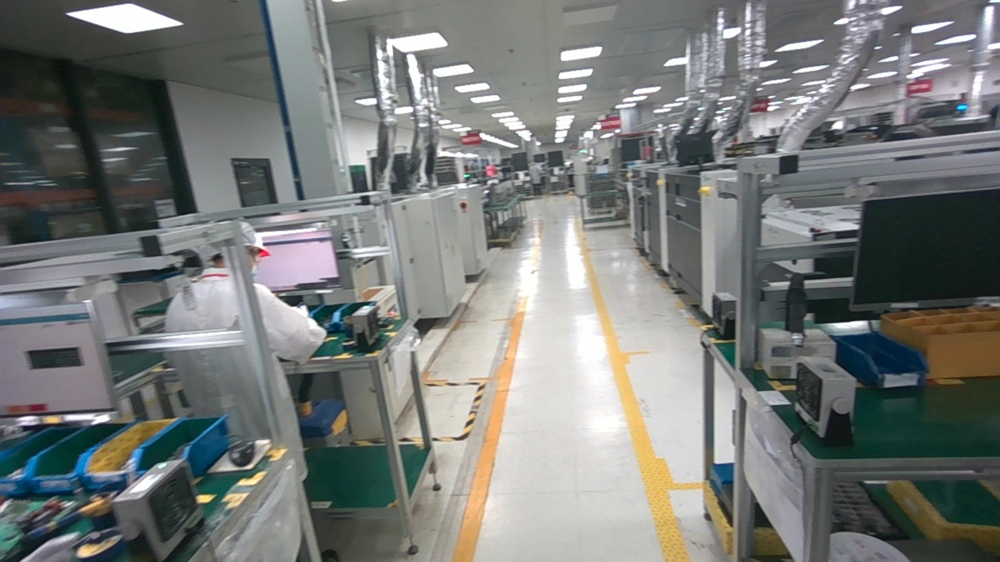

**Dataset:** `job62.zip`  
**Image:** `QuocHung__screen_on_off_outdoor_pm_20260908_130831__000580.jpg`  
**Kích thước:** 1920 × 1080

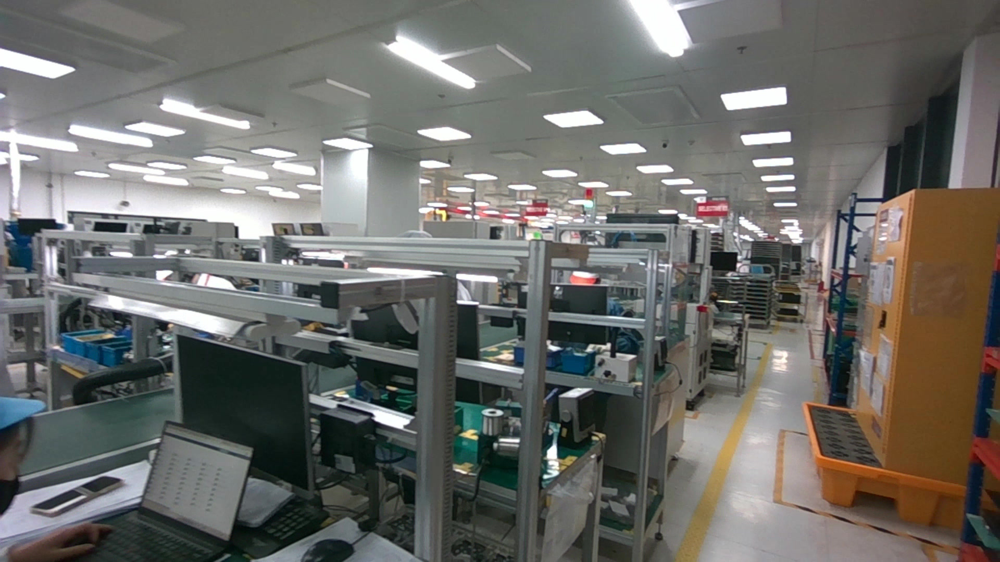

In [ ]:
import zipfile
from io import BytesIO
from PIL import Image
from IPython.display import display, Markdown

cases = [
    (
        "/content/job54.zip",
        "images/train/batch_004/NhatTan__layout_20260908_142002__001290.jpg"
    ),
    (
        "/content/job62.zip",
        "images/train/batch_007/QuocHung__screen_on_off_outdoor_pm_20260908_130831__000580.jpg"
    )
]

for zip_path, image_path in cases:
    print("\n" + "=" * 60)

    with zipfile.ZipFile(zip_path, "r") as z:
        image = Image.open(BytesIO(z.read(image_path))).convert("RGB")

        display(Markdown(
            f"**Dataset:** `{zip_path.split('/')[-1]}`  \n"
            f"**Image:** `{image_path.split('/')[-1]}`  \n"
            f"**Kích thước:** {image.size[0]} × {image.size[1]}"
        ))

        display(image)

In [ ]:
import zipfile
import os

cases = [
    (
        "/content/job54.zip",
        "NhatTan__layout_20260908_142002__001290.jpg"
    ),
    (
        "/content/job62.zip",
        "QuocHung__screen_on_off_outdoor_pm_20260908_130831__000580.jpg"
    )
]

for zip_path, target in cases:
    print("\n" + "=" * 60)
    print("DATASET:", os.path.basename(zip_path))

    with zipfile.ZipFile(zip_path) as z:
        lines = z.read("train.txt").decode("utf-8-sig").splitlines()

        matches = [
            (i, line.strip())
            for i, line in enumerate(lines, start=1)
            if target in line
        ]

        if matches:
            for line_no, path in matches:
                print("So dong trong train.txt:", line_no)
                print("Duong dan:", path)
        else:
            print("Khong tim thay trong train.txt.")


DATASET: job54.zip
So dong trong train.txt: 182
Duong dan: data/images/train/batch_004/NhatTan__layout_20260908_142002__001290.jpg

DATASET: job62.zip
So dong trong train.txt: 177
Duong dan: data/images/train/batch_007/QuocHung__screen_on_off_outdoor_pm_20260908_130831__000580.jpg


In [ ]:
import zipfile
import os

targets = [
    ("/content/job54.zip", "NhatTan__layout_20260908_142002__001290"),
    ("/content/job62.zip", "QuocHung__screen_on_off_outdoor_pm_20260908_130831__000580"),
]

for zip_path, stem in targets:
    print("\n" + "=" * 70)
    print(os.path.basename(zip_path), "|", stem)

    with zipfile.ZipFile(zip_path) as z:
        matches = [
            name for name in z.namelist()
            if stem in os.path.basename(name)
        ]

        if not matches:
            print("Khong tim thay file nao co ten nay.")
            continue

        for name in matches:
            info = z.getinfo(name)
            print(f"\nFile: {name}")
            print(f"Dung luong: {info.file_size} bytes")

            if name.lower().endswith(".txt"):
                content = z.read(name).decode(
                    "utf-8-sig", errors="replace"
                ).strip()
                print("Noi dung annotation:")
                print(content[:1500] if content else "(RONG)")


job54.zip | NhatTan__layout_20260908_142002__001290

File: images/train/batch_004/NhatTan__layout_20260908_142002__001290.jpg
Dung luong: 392194 bytes

job62.zip | QuocHung__screen_on_off_outdoor_pm_20260908_130831__000580

File: images/train/batch_007/QuocHung__screen_on_off_outdoor_pm_20260908_130831__000580.jpg
Dung luong: 399476 bytes


In [ ]:

from pathlib import Path
from zipfile import ZipFile
from collections import Counter
import re

# ============================================================
# 1. TIM FILE ZIP DA UPLOAD LEN COLAB
# ============================================================

candidates = list(Path("/content").glob("*.zip"))

if not candidates:
    raise FileNotFoundError(
        "Khong tim thay file ZIP trong /content. "
        "Hay upload ZIP vao Colab truoc."
    )

print("CAC FILE ZIP TIM THAY:")
for i, p in enumerate(candidates):
    print(f"[{i}] {p.name} - {p.stat().st_size / 1024**2:.2f} MB")

# Neu co nhieu ZIP, uu tien file job54.zip
zip_path = next(
    (p for p in candidates if p.name.lower() == "job54.zip"),
    max(candidates, key=lambda p: p.stat().st_mtime)
)

print(f"\nZIP DUOC KIEM TRA: {zip_path}")


# ============================================================
# 2. CAC HAM CHUAN HOA DUONG DAN
# ============================================================

def norm_path(s):
    s = s.strip().replace("\\", "/")
    while s.startswith("./"):
        s = s[2:]
    return s.lstrip("/")

def remove_data_prefix(s):
    s = norm_path(s)
    if s.startswith("data/"):
        s = s[len("data/"):]
    return s

def stem_of(s):
    return Path(norm_path(s)).stem

def is_image(s):
    return Path(s).suffix.lower() in {
        ".jpg", ".jpeg", ".png", ".bmp", ".webp"
    }


# ============================================================
# 3. DOC NOI DUNG ZIP
# ============================================================

with ZipFile(zip_path, "r") as z:
    all_names = [
        n for n in z.namelist()
        if not n.endswith("/")
    ]
    file_set = set(all_names)

    image_paths = [
        n for n in all_names
        if "/images/" in "/" + n.lower()
        and is_image(n)
    ]

    label_paths = [
        n for n in all_names
        if "/labels/" in "/" + n.lower()
        and n.lower().endswith(".txt")
        and Path(n).name.lower() != "train.txt"
    ]

    yaml_paths = [
        n for n in all_names
        if Path(n).name.lower() in {"data.yaml", "dataset.yaml"}
    ]

    train_paths = [
        n for n in all_names
        if Path(n).name.lower() == "train.txt"
    ]

    print("\n" + "=" * 65)
    print("TONG QUAN DATASET")
    print("=" * 65)
    print("Tong file trong ZIP:", len(all_names))
    print("So anh:", len(image_paths))
    print("So file label TXT:", len(label_paths))
    print("YAML:", yaml_paths)
    print("Train list:", train_paths)

    # Tao tap stem cua anh va label.
    image_stems = Counter(stem_of(p) for p in image_paths)
    label_stems = Counter(stem_of(p) for p in label_paths)

    image_stems_set = set(image_stems)
    label_stems_set = set(label_stems)

    missing_labels = sorted(image_stems_set - label_stems_set)
    orphan_labels = sorted(label_stems_set - image_stems_set)

    print("\n" + "=" * 65)
    print("DOI CHIEU ANH VA LABEL THEO STEM")
    print("=" * 65)
    print("So stem anh:", len(image_stems_set))
    print("So stem label:", len(label_stems_set))
    print("Anh khong co label theo stem:", len(missing_labels))
    print("Label khong co anh theo stem:", len(orphan_labels))
    print("Stem anh trung lap:", sum(v > 1 for v in image_stems.values()))
    print("Stem label trung lap:", sum(v > 1 for v in label_stems.values()))

    print("\nCAC ANH THIEU LABEL (toi da 30):")
    for s in missing_labels[:30]:
        print(" ", s)

    print("\nCAC LABEL KHONG CO ANH (toi da 30):")
    for s in orphan_labels[:30]:
        print(" ", s)

    # --------------------------------------------------------
    # 4. KIEM TRA RIENG ANH 001290
    # --------------------------------------------------------

    target = "NhatTan__layout_20260908_142002__001290"

    target_images = [
        p for p in image_paths if stem_of(p) == target
    ]
    target_labels = [
        p for p in label_paths if stem_of(p) == target
    ]

    print("\n" + "=" * 65)
    print("KIEM TRA ANH CAN XAC MINH")
    print("=" * 65)
    print("Stem:", target)
    print("Anh tim thay:", len(target_images))
    for p in target_images:
        print("  IMAGE:", p)

    print("Label tim thay:", len(target_labels))
    for p in target_labels:
        print("  LABEL:", p)
        content = z.read(p).decode("utf-8-sig", errors="replace")
        lines = [line.strip() for line in content.splitlines()
                 if line.strip()]
        print("  So dong annotation:", len(lines))
        print("  Vi du 3 dong dau:")
        for line in lines[:3]:
            print("   ", line[:200])

    if target_images and target_labels:
        print("\nKET LUAN: CO CA ANH VA FILE LABEL CUNG STEM.")
    elif target_images and not target_labels:
        print("\nKET LUAN: CO ANH NHUNG KHONG CO LABEL CUNG STEM.")
    elif target_labels and not target_images:
        print("\nKET LUAN: CO LABEL NHUNG KHONG TIM THAY ANH.")
    else:
        print("\nKET LUAN: KHONG TIM THAY ANH HOAC LABEL THEO STEM.")

    # --------------------------------------------------------
    # 5. DOC train.txt VA KIEM TRA DUONG DAN
    # --------------------------------------------------------

    print("\n" + "=" * 65)
    print("KIEM TRA train.txt")
    print("=" * 65)

    train_entries = []
    for p in train_paths:
        text = z.read(p).decode("utf-8-sig", errors="replace")
        train_entries.extend(
            line.strip() for line in text.splitlines()
            if line.strip()
        )

    print("So dong train.txt:", len(train_entries))

    # So khop ca duong dan goc va duong dan bo prefix data/
    archive_norm = {norm_path(p) for p in all_names}
    archive_without_data = {remove_data_prefix(p) for p in all_names}

    direct_matches = 0
    normalized_matches = 0
    missing_train_images = []

    for line_no, entry in enumerate(train_entries, start=1):
        normalized = norm_path(entry)
        normalized2 = remove_data_prefix(entry)

        exists = (
            normalized in archive_norm
            or normalized2 in archive_norm
            or normalized in archive_without_data
            or normalized2 in archive_without_data
        )

        if normalized in archive_norm:
            direct_matches += 1
        if exists:
            normalized_matches += 1
        else:
            missing_train_images.append((line_no, entry))

    print("Duong dan khop truc tiep:", direct_matches)
    print("Duong dan khop sau chuan hoa:", normalized_matches)
    print("Anh trong train.txt khong tim thay:", len(missing_train_images))

    for line_no, entry in missing_train_images[:20]:
        print(f"  Dong {line_no}: {entry}")

    # --------------------------------------------------------
    # 6. KIEM TRA DINH DANG POLYGON YOLO SEGMENTATION
    # --------------------------------------------------------

    print("\n" + "=" * 65)
    print("KIEM TRA DINH DANG LABEL")
    print("=" * 65)

    class_counts = Counter()
    empty_labels = []
    bad_lines = []
    total_instances = 0

    for p in label_paths:
        content = z.read(p).decode("utf-8-sig", errors="replace")
        lines = [line.strip() for line in content.splitlines()
                 if line.strip()]

        if not lines:
            empty_labels.append(p)
            continue

        for line_no, line in enumerate(lines, start=1):
            parts = line.split()

            # Polygon YOLO: class_id, x1, y1, x2, y2, ...
            if len(parts) < 7 or (len(parts) - 1) % 2 != 0:
                bad_lines.append((p, line_no, "Sai so luong toa do", line[:120]))
                continue

            try:
                cls = int(parts[0])
                coords = [float(v) for v in parts[1:]]
            except ValueError:
                bad_lines.append((p, line_no, "Khong doc duoc so", line[:120]))
                continue

            if cls < 0:
                bad_lines.append((p, line_no, "Class ID am", line[:120]))
                continue

            if any(v < 0 or v > 1 for v in coords):
                bad_lines.append((p, line_no, "Toa do ngoai [0,1]", line[:120]))
                continue

            class_counts[cls] += 1
            total_instances += 1

    print("Tong instance polygon hop le:", total_instances)
    print("Instance theo class ID:", dict(sorted(class_counts.items())))
    print("File label rong:", len(empty_labels))
    print("Dong can kiem tra:", len(bad_lines))

    for item in empty_labels[:10]:
        print("  LABEL RONG:", item)

    for item in bad_lines[:20]:
        print("  LOI:", item)

    # --------------------------------------------------------
    # 7. DOC data.yaml
    # --------------------------------------------------------

    print("\n" + "=" * 65)
    print("NOI DUNG YAML")
    print("=" * 65)

    for p in yaml_paths:
        print(f"\n--- {p} ---")
        print(z.read(p).decode("utf-8-sig", errors="replace")[:5000])

print("\nHOAN TAT KIEM TRA.")


CAC FILE ZIP TIM THAY:
[0] job62.zip - 114.56 MB
[1] job54.zip - 110.10 MB

ZIP DUOC KIEM TRA: /content/job54.zip

TONG QUAN DATASET
Tong file trong ZIP: 596
So anh: 297
So file label TXT: 297
YAML: ['data.yaml']
Train list: ['train.txt']

DOI CHIEU ANH VA LABEL THEO STEM
So stem anh: 297
So stem label: 297
Anh khong co label theo stem: 0
Label khong co anh theo stem: 0
Stem anh trung lap: 0
Stem label trung lap: 0

CAC ANH THIEU LABEL (toi da 30):

CAC LABEL KHONG CO ANH (toi da 30):

KIEM TRA ANH CAN XAC MINH
Stem: NhatTan__layout_20260908_142002__001290
Anh tim thay: 1
  IMAGE: images/train/batch_004/NhatTan__layout_20260908_142002__001290.jpg
Label tim thay: 1
  LABEL: labels/train/batch_004/NhatTan__layout_20260908_142002__001290.txt
  So dong annotation: 2
  Vi du 3 dong dau:
    0 0.257208 0.414231 0.259130 0.415593 0.260667 0.417870 0.261688 0.420833 0.262203 0.424250 0.262583 0.428343 0.262969 0.431759 0.263354 0.435176 0.263865 0.438593 0.264891 0.441546 0.266297 0.444056 
  

In [ ]:
import zipfile
from pathlib import Path
from collections import Counter, defaultdict

ZIP_FILES = [
    "/content/job54.zip",
    "/content/job62.zip",
]

IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}


def normalize(path):
    return path.replace("\\", "/").lstrip("./")


def session_name(image_path):
    # Vi du:
    # NhatTan__layout_20260908_142002__001290.jpg
    # -> NhatTan__layout_20260908_142002
    stem = Path(image_path).stem
    parts = stem.rsplit("__", 1)

    if len(parts) == 2 and parts[1].isdigit():
        return parts[0]

    return stem


all_sessions = defaultdict(set)
all_stems_by_zip = {}
all_missing_labels = {}
all_image_stems = {}

for zip_path in ZIP_FILES:
    path = Path(zip_path)

    print("\n" + "=" * 70)
    print("DATASET:", path.name)
    print("=" * 70)

    if not path.exists():
        print("KHONG TIM THAY FILE:", zip_path)
        continue

    with zipfile.ZipFile(path) as z:
        files = [
            normalize(n) for n in z.namelist()
            if not n.endswith("/")
        ]
        file_set = set(files)

        images = [
            n for n in files
            if n.startswith("images/")
            and Path(n).suffix.lower() in IMAGE_EXTS
        ]

        labels = [
            n for n in files
            if n.startswith("labels/")
            and Path(n).suffix.lower() == ".txt"
        ]

        # Doi chieu label theo duong dan tuong doi,
        # khong chi dua vao ten file.
        label_set = set(labels)
        missing = []

        for image in images:
            relative = image[len("images/"):]
            expected_label = (
                "labels/" + str(Path(relative).with_suffix(".txt"))
            ).replace("\\", "/")

            if expected_label not in label_set:
                missing.append((image, expected_label))

        groups = defaultdict(list)
        for image in images:
            group = session_name(Path(image).name)
            groups[group].append(image)
            all_sessions[group].add(path.name)

        print("So anh:", len(images))
        print("So label TXT:", len(labels))
        print("Anh thieu label theo duong dan:", len(missing))

        for img, expected in missing[:10]:
            print("  ANH:", img)
            print("  LABEL CAN CO:", expected)

        all_missing_labels[path.name] = missing
        all_stems_by_zip[path.name] = set(
            Path(p).stem for p in images
        )
        all_image_stems[path.name] = set(
            Path(p).stem for p in images
        )

        print("\nSo phien quay:", len(groups))
        print("So frame theo tung phien quay:")

        for group, frames in sorted(
            groups.items(),
            key=lambda item: (-len(item[1]), item[0])
        ):
            print(f"  {group}: {len(frames)} frame")

# Kiem tra ten anh trung giua hai ZIP
if len(all_image_stems) == 2:
    names = list(all_image_stems.keys())
    common = all_image_stems[names[0]] & all_image_stems[names[1]]

    print("\n" + "=" * 70)
    print("KIEM TRA TRUNG LAP")
    print("=" * 70)
    print("So stem trung giua hai ZIP:", len(common))
    for stem in sorted(common)[:20]:
        print(" ", stem)


DATASET: job54.zip
So anh: 297
So label TXT: 297
Anh thieu label theo duong dan: 0

So phien quay: 6
So frame theo tung phien quay:
  NhatTan__layout_20260908_142209: 90 frame
  NhatTan__layout_20260908_142002: 82 frame
  NhatTan__crowd_20260908_143116: 45 frame
  BaoAnh__screen_on_off_outdoor_pm_20260908_130620: 43 frame
  BaoAnh__screen_on_off_outdoor_pm_20260908_131056: 26 frame
  BaoAnh__screen_on_off_20260908_113356: 11 frame

DATASET: job62.zip
So anh: 298
So label TXT: 298
Anh thieu label theo duong dan: 0

So phien quay: 4
So frame theo tung phien quay:
  QuocHung__screen_on_off_outdoor_pm_20260908_130831: 171 frame
  QuocHung__screen_on_off_outdoor_pm_20260908_130802: 63 frame
  QuocHung__phone_20260908_133350: 38 frame
  QuocHung__screen_on_off_outdoor_pm_20260908_130658: 26 frame

KIEM TRA TRUNG LAP
So stem trung giua hai ZIP: 0


In [ ]:
import zipfile
from pathlib import Path, PurePosixPath
from collections import Counter, defaultdict
from itertools import combinations

ZIP_FILES = [
    "/content/job54.zip",
    "/content/job62.zip",
]

IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

# session -> {"images": int, "classes": Counter}
sessions = defaultdict(lambda: {
    "images": 0,
    "classes": Counter()
})

total_images = 0
total_classes = Counter()

def get_session(filename):
    stem = PurePosixPath(filename).stem
    parts = stem.rsplit("__", 1)

    if len(parts) == 2 and parts[1].isdigit():
        return parts[0]

    return stem

for zip_path in ZIP_FILES:
    with zipfile.ZipFile(zip_path) as z:
        members = set(
            n for n in z.namelist()
            if not n.endswith("/")
        )

        images = sorted(
            n for n in members
            if n.startswith("images/")
            and PurePosixPath(n).suffix.lower() in IMAGE_EXTS
        )

        labels = {
            n for n in members
            if n.startswith("labels/")
            and PurePosixPath(n).suffix.lower() == ".txt"
        }

        for image_path in images:
            relative = image_path[len("images/"):]
            label_path = str(
                PurePosixPath("labels") /
                PurePosixPath(relative).with_suffix(".txt")
            )

            if label_path not in labels:
                raise ValueError(
                    f"Thieu label: {image_path}\n"
                    f"Label mong doi: {label_path}"
                )

            session = get_session(PurePosixPath(image_path).name)
            sessions[session]["images"] += 1
            total_images += 1

            content = z.read(label_path).decode(
                "utf-8-sig", errors="replace"
            )

            for line in content.splitlines():
                parts = line.split()
                if not parts:
                    continue

                cls = int(parts[0])
                sessions[session]["classes"][cls] += 1
                total_classes[cls] += 1

groups = sorted(sessions)
num_classes = len(total_classes)

print("TONG SO ANH:", total_images)
print("SO PHIEN QUAY:", len(groups))
print("TONG INSTANCE THEO CLASS:", dict(sorted(total_classes.items())))

# Liet ke tung phien quay
print("\nTHONG KE THEO PHIEN QUAY:")
for group in groups:
    info = sessions[group]
    print(
        f"{group}: {info['images']} anh | "
        f"classes={dict(sorted(info['classes'].items()))}"
    )

# Tim cac to hop phien quay validation trong khoang 15%-25%
candidates = []

for r in range(1, len(groups)):
    for val_groups in combinations(groups, r):
        val_images = sum(sessions[g]["images"] for g in val_groups)
        val_ratio = val_images / total_images

        if not 0.15 <= val_ratio <= 0.25:
            continue

        val_counts = Counter()
        for g in val_groups:
            val_counts.update(sessions[g]["classes"])

        missing_classes = [
            c for c in total_classes
            if val_counts[c] == 0
        ]

        class_deviation = sum(
            abs(val_counts[c] / total_classes[c] - val_ratio)
            for c in total_classes
        ) / max(1, num_classes)

        # Uu tien: ty le anh gan 20%, phan bo class can doi,
        # va khong thieu class trong validation.
        score = (
            3.0 * abs(val_ratio - 0.20)
            + 2.0 * class_deviation
            + 0.5 * len(missing_classes)
        )

        candidates.append({
            "score": score,
            "groups": val_groups,
            "images": val_images,
            "ratio": val_ratio,
            "counts": val_counts,
            "missing": missing_classes,
            "deviation": class_deviation,
        })

candidates.sort(key=lambda x: x["score"])

print("\n" + "=" * 65)
print("5 PHUONG AN CHIA VALIDATION TOT NHAT")
print("=" * 65)

for i, item in enumerate(candidates[:5], start=1):
    print(f"\nPHUONG AN {i}")
    print(
        f"Validation: {item['images']}/{total_images} anh "
        f"({item['ratio']:.1%})"
    )
    print("Class thieu trong validation:", item["missing"])
    print("Ty le instance validation theo class:")

    for cls in sorted(total_classes):
        ratio = item["counts"][cls] / total_classes[cls]
        print(
            f"  Class {cls}: {item['counts'][cls]}/"
            f"{total_classes[cls]} ({ratio:.1%})"
        )

    print("Cac phien quay validation:")
    for group in item["groups"]:
        print("  -", group)

if not candidates:
    print(
        "Khong tim thay phuong an trong khoang 15%-25%. "
        "Can xem lai muc tieu chia theo nhom."
    )

TONG SO ANH: 595
SO PHIEN QUAY: 10
TONG INSTANCE THEO CLASS: {0: 2429, 1: 870, 2: 876, 3: 866, 4: 519, 5: 2330}

THONG KE THEO PHIEN QUAY:
BaoAnh__screen_on_off_20260908_113356: 11 anh | classes={0: 11, 4: 22, 5: 66}
BaoAnh__screen_on_off_outdoor_pm_20260908_130620: 43 anh | classes={0: 136, 1: 19, 2: 61, 3: 75, 4: 46, 5: 159}
BaoAnh__screen_on_off_outdoor_pm_20260908_131056: 26 anh | classes={0: 37, 1: 8, 2: 19, 3: 41, 4: 40, 5: 61}
NhatTan__crowd_20260908_143116: 45 anh | classes={0: 388, 1: 77, 2: 109, 3: 106, 4: 58, 5: 348}
NhatTan__layout_20260908_142002: 82 anh | classes={0: 224, 1: 118, 2: 98, 3: 97, 4: 19, 5: 221}
NhatTan__layout_20260908_142209: 90 anh | classes={0: 716, 1: 178, 2: 138, 3: 166, 4: 95, 5: 515}
QuocHung__phone_20260908_133350: 38 anh | classes={0: 56, 2: 32, 3: 47, 4: 26, 5: 65}
QuocHung__screen_on_off_outdoor_pm_20260908_130658: 26 anh | classes={0: 130, 1: 64, 2: 86, 3: 69, 4: 85, 5: 125}
QuocHung__screen_on_off_outdoor_pm_20260908_130802: 63 anh | classes={0:

In [ ]:
import zipfile
import shutil
from pathlib import Path, PurePosixPath
from collections import Counter, defaultdict

# ============================================================
# CAU HINH
# ============================================================

ZIP_FILES = [
    "/content/job54.zip",
    "/content/job62.zip",
]

OUT_DIR = Path("/content/yolo11_seg_dataset")

CLASS_NAMES = {
    0: "hat",
    1: "gloves",
    2: "mask",
    3: "pants",
    4: "shoes",
    5: "long-sleeved shirt",
}

# Phuong an 1: giu nguyen cac phien quay validation
VAL_SESSIONS = {
    "BaoAnh__screen_on_off_20260908_113356",
    "NhatTan__layout_20260908_142002",
    "QuocHung__screen_on_off_outdoor_pm_20260908_130658",
}

IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}


def get_session(filename):
    stem = PurePosixPath(filename).stem
    parts = stem.rsplit("__", 1)

    if len(parts) == 2 and parts[1].isdigit():
        return parts[0]

    raise ValueError(
        f"Khong suy ra duoc phien quay tu ten file: {filename}"
    )


# ============================================================
# 1. KIEM TRA FILE ZIP
# ============================================================

for zip_file in ZIP_FILES:
    if not Path(zip_file).exists():
        raise FileNotFoundError(
            f"Khong tim thay {zip_file}. "
            "Hay kiem tra ten file trong /content."
        )

print("Da tim thay ca hai ZIP.")

# Xoa dataset tao tu lan chay truoc neu co.
# Hai file ZIP goc se duoc giu nguyen.
if OUT_DIR.exists():
    shutil.rmtree(OUT_DIR)

for split in ("train", "val"):
    (OUT_DIR / "images" / split).mkdir(parents=True)
    (OUT_DIR / "labels" / split).mkdir(parents=True)


# ============================================================
# 2. DOC ZIP, CHIA THEO PHIEN QUAY VA SAO CHEP DU LIEU
# ============================================================

split_images = Counter()
split_instances = Counter()
split_classes = defaultdict(Counter)
split_sessions = defaultdict(Counter)
seen_stems = set()
all_sessions = set()
source_report = []

for zip_file in ZIP_FILES:
    print(f"\nDang xu ly: {Path(zip_file).name}")

    with zipfile.ZipFile(zip_file, "r") as z:
        members = {
            name for name in z.namelist()
            if not name.endswith("/")
        }

        image_paths = sorted(
            name for name in members
            if name.startswith("images/")
            and PurePosixPath(name).suffix.lower() in IMAGE_EXTS
        )

        label_paths = {
            name for name in members
            if name.startswith("labels/")
            and PurePosixPath(name).suffix.lower() == ".txt"
        }

        copied = Counter()

        for image_path in image_paths:
            relative_image = image_path[len("images/"):]
            relative_posix = PurePosixPath(relative_image)

            label_path = str(
                PurePosixPath("labels") /
                relative_posix.with_suffix(".txt")
            )

            if label_path not in label_paths:
                raise ValueError(
                    f"THIEU LABEL:\n"
                    f"Image: {image_path}\n"
                    f"Label can co: {label_path}"
                )

            filename = relative_posix.name
            stem = relative_posix.stem

            # Khong de hai file cung ten bi ghi de len nhau.
            if stem in seen_stems:
                raise ValueError(
                    f"TRUNG TEN ANH GIUA CAC DATASET: {stem}"
                )
            seen_stems.add(stem)

            session = get_session(filename)
            all_sessions.add(session)

            split = "val" if session in VAL_SESSIONS else "train"

            # Doc va kiem tra annotation polygon co ban.
            content = z.read(label_path).decode(
                "utf-8-sig", errors="replace"
            ).strip()

            if not content:
                raise ValueError(
                    f"Label rong: {label_path}"
                )

            lines = content.splitlines()
            instance_count = 0

            for line_no, line in enumerate(lines, start=1):
                parts = line.split()

                if len(parts) < 7 or (len(parts) - 1) % 2 != 0:
                    raise ValueError(
                        f"Polygon sai dinh dang: {label_path}, "
                        f"dong {line_no}"
                    )

                try:
                    cls = int(parts[0])
                    coords = [float(x) for x in parts[1:]]
                except ValueError:
                    raise ValueError(
                        f"Toa do khong hop le: {label_path}, "
                        f"dong {line_no}"
                    )

                if cls not in CLASS_NAMES:
                    raise ValueError(
                        f"Class ID khong hop le {cls}: {label_path}"
                    )

                if any(x < 0 or x > 1 for x in coords):
                    raise ValueError(
                        f"Toa do ngoai [0, 1]: {label_path}, "
                        f"dong {line_no}"
                    )

                split_classes[split][cls] += 1
                instance_count += 1

            # Sao chep anh va label vao thu muc flat.
            output_image = OUT_DIR / "images" / split / filename
            output_label = OUT_DIR / "labels" / split / f"{stem}.txt"

            if output_image.exists() or output_label.exists():
                raise FileExistsError(
                    f"File output da ton tai: {stem}"
                )

            with z.open(image_path) as src, open(output_image, "wb") as dst:
                shutil.copyfileobj(src, dst)

            output_label.write_text(
                content + "\n",
                encoding="utf-8"
            )

            split_images[split] += 1
            split_instances[split] += instance_count
            split_sessions[split][session] += 1
            copied[split] += 1

        source_report.append((Path(zip_file).name, copied))

        print("Anh da sao chep:", dict(copied))


# ============================================================
# 3. TAO data.yaml
# ============================================================

yaml_lines = [
    f"path: {OUT_DIR}",
    "train: images/train",
    "val: images/val",
    "names:",
]

for cls, name in CLASS_NAMES.items():
    yaml_lines.append(f"  {cls}: '{name}'")

yaml_path = OUT_DIR / "data.yaml"
yaml_path.write_text(
    "\n".join(yaml_lines) + "\n",
    encoding="utf-8"
)


# ============================================================
# 4. KIEM TRA DATASET SAU KHI TAO
# ============================================================

print("\n" + "=" * 65)
print("KET QUA DATASET")
print("=" * 65)

for split in ("train", "val"):
    image_dir = OUT_DIR / "images" / split
    label_dir = OUT_DIR / "labels" / split

    images = [
        p for p in image_dir.iterdir()
        if p.is_file() and p.suffix.lower() in IMAGE_EXTS
    ]
    labels = list(label_dir.glob("*.txt"))

    image_stems = {p.stem for p in images}
    label_stems = {p.stem for p in labels}

    print(f"\n{split.upper()}")
    print("So anh:", len(images))
    print("So label:", len(labels))
    print("So instance polygon:", split_instances[split])
    print("Instance theo class:", dict(sorted(split_classes[split].items())))
    print("So phien quay:", len(split_sessions[split]))

    missing_label = image_stems - label_stems
    missing_image = label_stems - image_stems

    print("Anh thieu label:", len(missing_label))
    print("Label thieu anh:", len(missing_image))

    if missing_label or missing_image:
        raise RuntimeError(
            f"Dataset {split} co anh/label khong khop."
        )

    for session, count in sorted(split_sessions[split].items()):
        print(f"  {session}: {count} anh")

print("\nTong anh:", sum(split_images.values()))
print("Ty le validation: "
      f"{split_images['val'] / sum(split_images.values()):.1%}")
print("Dataset YAML:", yaml_path)
print("Thu muc dataset:", OUT_DIR)

print("\nHOAN TAT. Hai ZIP goc van duoc giu nguyen.")

Da tim thay ca hai ZIP.

Dang xu ly: job54.zip
Anh da sao chep: {'val': 93, 'train': 204}

Dang xu ly: job62.zip
Anh da sao chep: {'train': 272, 'val': 26}

KET QUA DATASET

TRAIN
So anh: 476
So label: 476
So instance polygon: 6455
Instance theo class: {0: 2064, 1: 688, 2: 692, 3: 700, 4: 393, 5: 1918}
So phien quay: 7
Anh thieu label: 0
Label thieu anh: 0
  BaoAnh__screen_on_off_outdoor_pm_20260908_130620: 43 anh
  BaoAnh__screen_on_off_outdoor_pm_20260908_131056: 26 anh
  NhatTan__crowd_20260908_143116: 45 anh
  NhatTan__layout_20260908_142209: 90 anh
  QuocHung__phone_20260908_133350: 38 anh
  QuocHung__screen_on_off_outdoor_pm_20260908_130802: 63 anh
  QuocHung__screen_on_off_outdoor_pm_20260908_130831: 171 anh

VAL
So anh: 119
So label: 119
So instance polygon: 1435
Instance theo class: {0: 365, 1: 182, 2: 184, 3: 166, 4: 126, 5: 412}
So phien quay: 3
Anh thieu label: 0
Label thieu anh: 0
  BaoAnh__screen_on_off_20260908_113356: 11 anh
  NhatTan__layout_20260908_142002: 82 anh
  Q

In [ ]:
%pip install -q ultralytics albumentations

import torch
import ultralytics
import albumentations as A
from pathlib import Path

print("=" * 55)
print("KIEM TRA MOI TRUONG")
print("=" * 55)

print("Ultralytics:", ultralytics.__version__)
print("Albumentations:", A.__version__)
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("GPU memory: %.2f GB" % (
        torch.cuda.get_device_properties(0).total_memory
        / 1024**3
    ))
else:
    raise RuntimeError(
        "Chua co GPU. Vao Runtime > Change runtime type > T4 GPU."
    )

dataset_dir = Path("/content/yolo11_seg_dataset")
yaml_file = dataset_dir / "data.yaml"

assert yaml_file.exists(), "Khong tim thay data.yaml"

for split in ["train", "val"]:
    image_dir = dataset_dir / "images" / split
    label_dir = dataset_dir / "labels" / split

    images = list(image_dir.glob("*"))
    labels = list(label_dir.glob("*.txt"))

    print(f"\n{split.upper()}:")
    print("Images:", len(images))
    print("Labels:", len(labels))

    assert len(images) == len(labels), (
        f"So anh va label khong khop trong {split}"
    )

print("\nMOI TRUONG VA DATASET: OK")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.0/47.0 kB 1.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 32.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.6/97.6 kB 10.1 MB/s eta 0:00:00
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
KIEM TRA MOI TRUONG
Ultralytics: 8.4.183
Albumentations: 2.0.8
PyTorch: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4
GPU memory: 14.56 GB

TRAIN:
Images: 476
Labels: 476

VAL:
Images: 119
Labels: 119

MOI TRUONG VA DATASET: OK


In [ ]:
import torch
import albumentations as A
from pathlib import Path
from ultralytics import YOLO

# ============================================================
# 1. KIEM TRA DATASET VA GPU
# ============================================================

DATA_YAML = "/content/yolo11_seg_dataset/data.yaml"

assert Path(DATA_YAML).exists(), (
    f"Khong tim thay dataset config: {DATA_YAML}"
)

assert torch.cuda.is_available(), (
    "Khong tim thay GPU CUDA. Hay bat GPU trong Colab."
)

print("GPU:", torch.cuda.get_device_name(0))
print("Dataset:", DATA_YAML)

# ============================================================
# 2. CUSTOM AUGMENTATION
# ============================================================

custom_augmentations = [
    # Blur va motion blur: mo phong anh bi rung/chuyen dong
    A.OneOf(
        [
            A.Blur(blur_limit=5, p=1.0),
            A.MotionBlur(blur_limit=5, p=1.0),
        ],
        p=0.15,
    ),

    # Thay doi nhe do sang va do tuong phan
    A.RandomBrightnessContrast(
        brightness_limit=0.12,
        contrast_limit=0.12,
        p=0.20,
    ),

    # Them nhieu nhe
    A.GaussNoise(
        std_range=(0.01, 0.03),
        p=0.08,
    ),
]

# ============================================================
# 3. NAP MODEL PRETRAINED
# ============================================================

model = YOLO("yolo11s-seg.pt")

# ============================================================
# 4. CAU HINH HUAN LUYEN
# ============================================================

results = model.train(
    # Dataset
    data=DATA_YAML,
    imgsz=640,

    # Training
    epochs=100,
    batch=8,
    device=0,
    workers=2,

    # Optimizer va learning rate
    optimizer="auto",
    patience=25,
    seed=42,
    deterministic=True,
    amp=True,

    # Geometric augmentation
    fliplr=0.5,
    flipud=0.0,
    degrees=5.0,
    translate=0.10,
    scale=0.50,
    shear=0.0,
    perspective=0.0,

    # Color augmentation
    hsv_h=0.015,
    hsv_s=0.50,
    hsv_v=0.30,

    # Mosaic va mixup
    mosaic=0.80,
    mixup=0.0,
    close_mosaic=10,

    # Custom Albumentations
    augmentations=custom_augmentations,

    # Validation va luu ket qua
    val=True,
    plots=True,
    save=True,
    save_period=10,

    # Thu muc ket qua
    project="/content/yolo11_seg_runs",
    name="yolo11s_seg_job54_job62",
    exist_ok=True,
)

print("\nHUAN LUYEN HOAN TAT.")
print("Thu muc ket qua:")
print("/content/yolo11_seg_runs/yolo11s_seg_job54_job62")

print("\nCheckpoint can giu lai:")
print("/content/yolo11_seg_runs/yolo11s_seg_job54_job62/weights/best.pt")

GPU: Tesla T4
Dataset: /content/yolo11_seg_dataset/data.yaml
Ultralytics 8.4.183 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, augmentations=[{'__version__': '2.0.8', 'transform': {'__class_fullname__': 'OneOf', 'p': 0.15, 'transforms': [{'__class_fullname__': 'Blur', 'p': 1.0, 'blur_limit': (3, 5)}, {'__class_fullname__': 'MotionBlur', 'p': 1.0, 'allow_shifted': True, 'angle_range': (0.0, 360.0), 'blur_limit': (3, 5), 'direction_range': (-1.0, 1.0)}]}}, {'__version__': '2.0.8', 'transform': {'__class_fullname__': 'RandomBrightnessContrast', 'p': 0.2, 'brightness_by_max': True, 'brightness_limit': (-0.12, 0.12), 'contrast_limit': (-0.12, 0.12), 'ensure_safe_range': False}}, {'__version__': '2.0.8', 'transform': {'__class_fullname__': 'GaussNoise', 'p': 0.08, 'mean_range': (0.0, 0.0), 'noise_scale_factor': 1.0, 'per_channel': True, 'std_range': (0.01, 0.03)}}], auto_augment=randaugment, batch=8, bg

Thu muc ket qua: /content/yolo11_seg_runs/yolo11s_seg_job54_job62

1. TRAINING CURVES


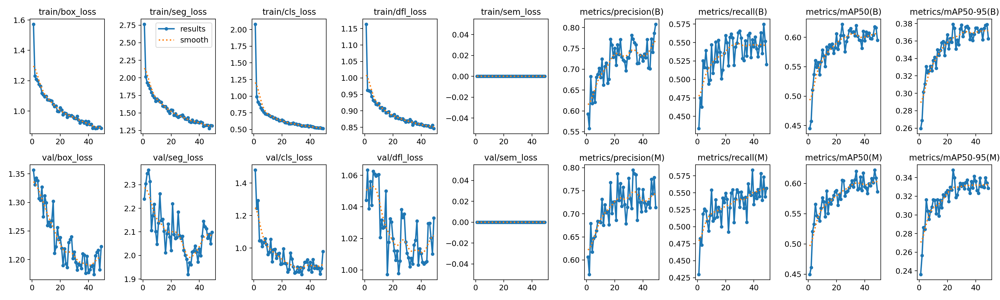


 MaskPR_curve.png


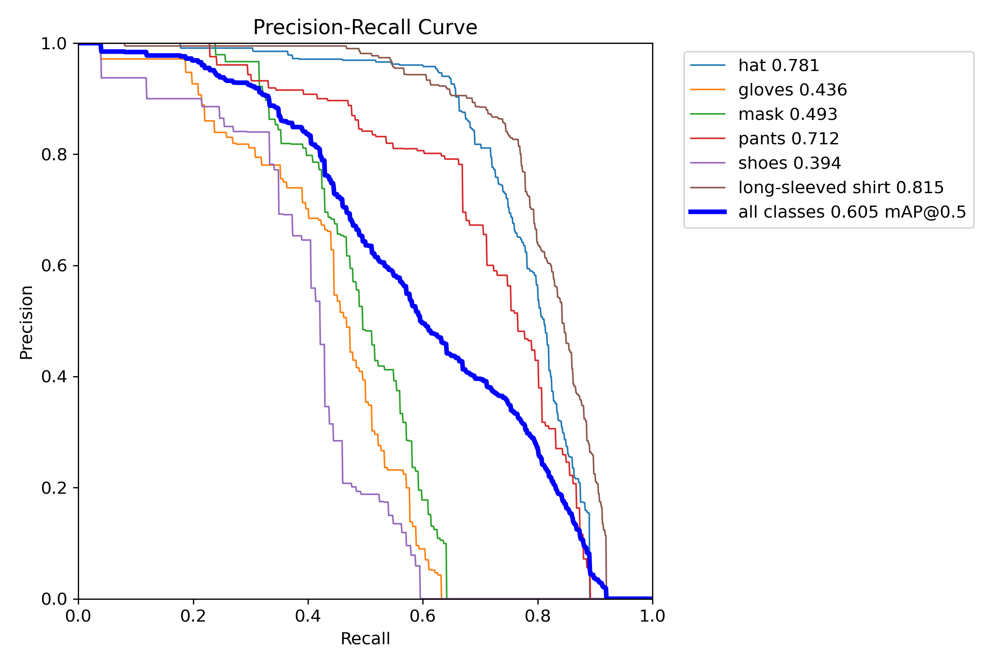


 MaskF1_curve.png


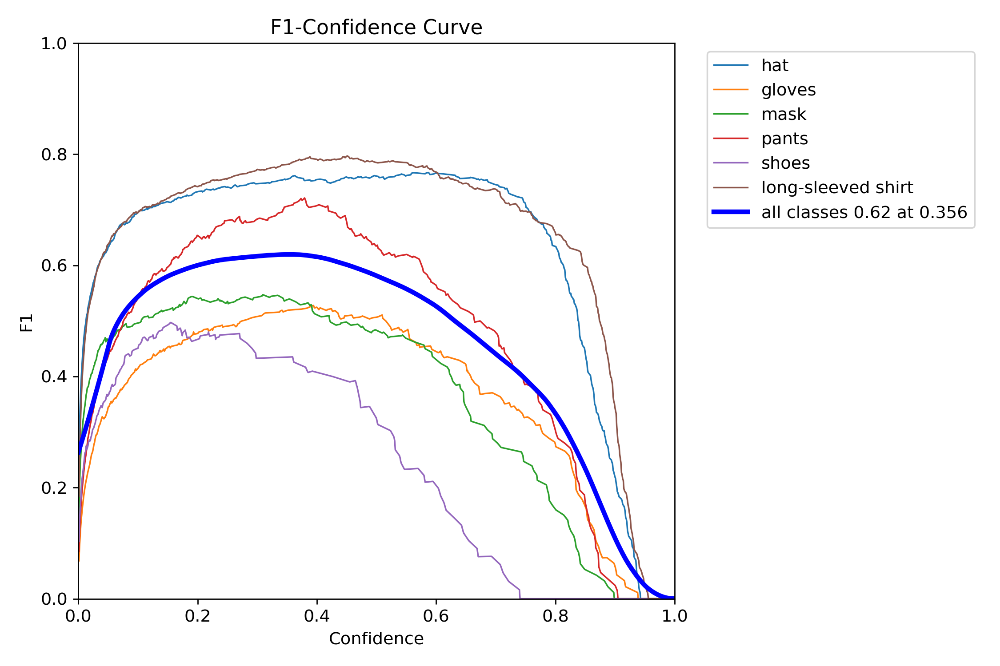


 MaskP_curve.png


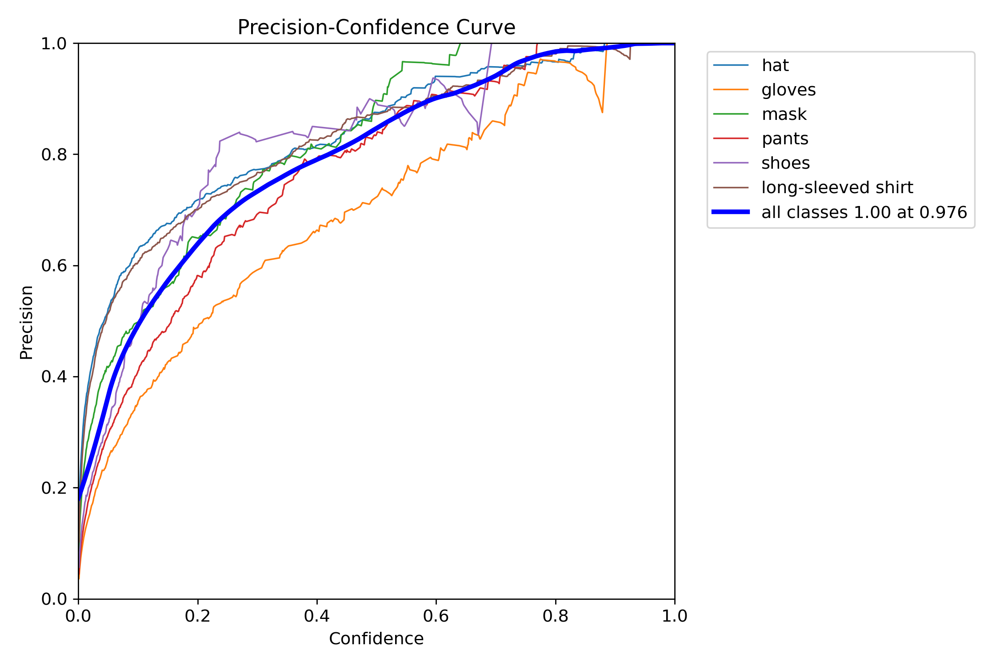


 MaskR_curve.png


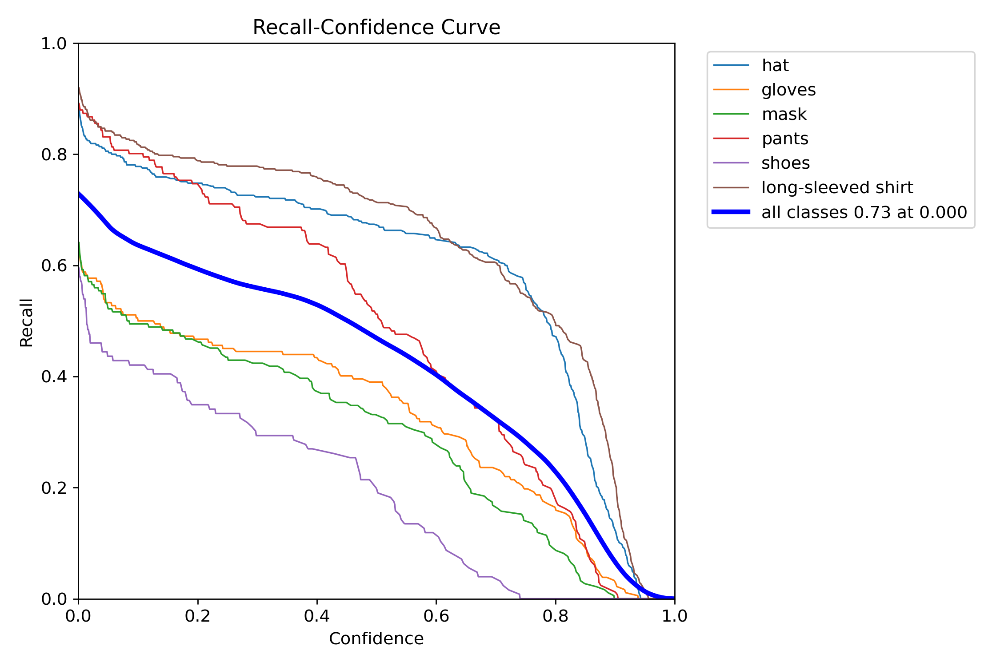


val_batch*_labels.jpg: tim thay 3 file
val_batch0_labels.jpg


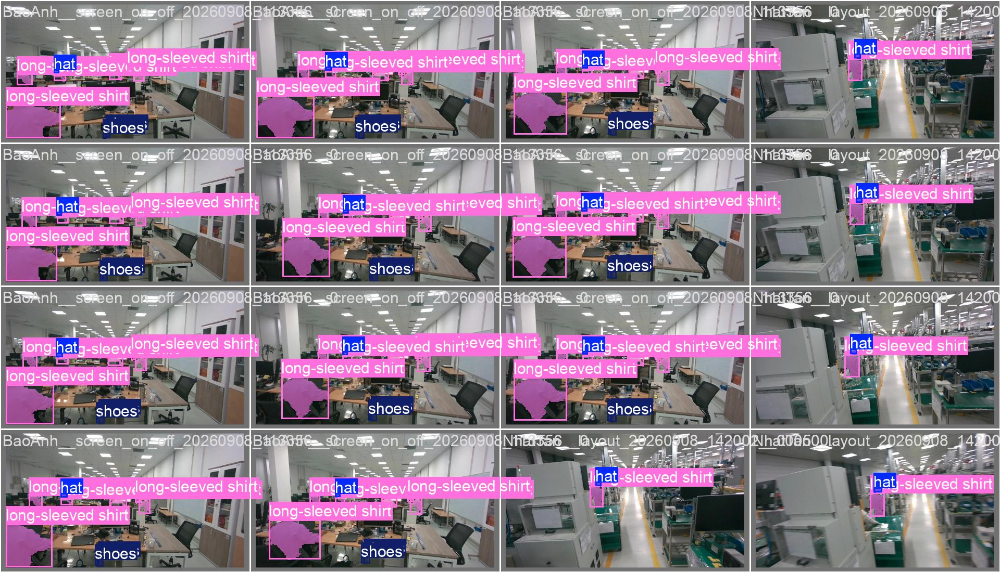

val_batch1_labels.jpg


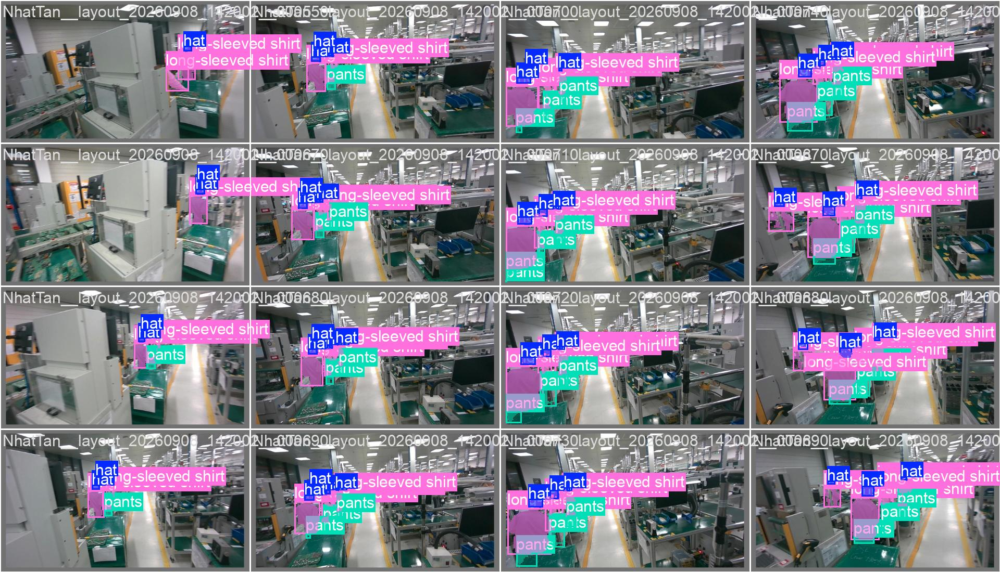


val_batch*_pred.jpg: tim thay 3 file
val_batch0_pred.jpg


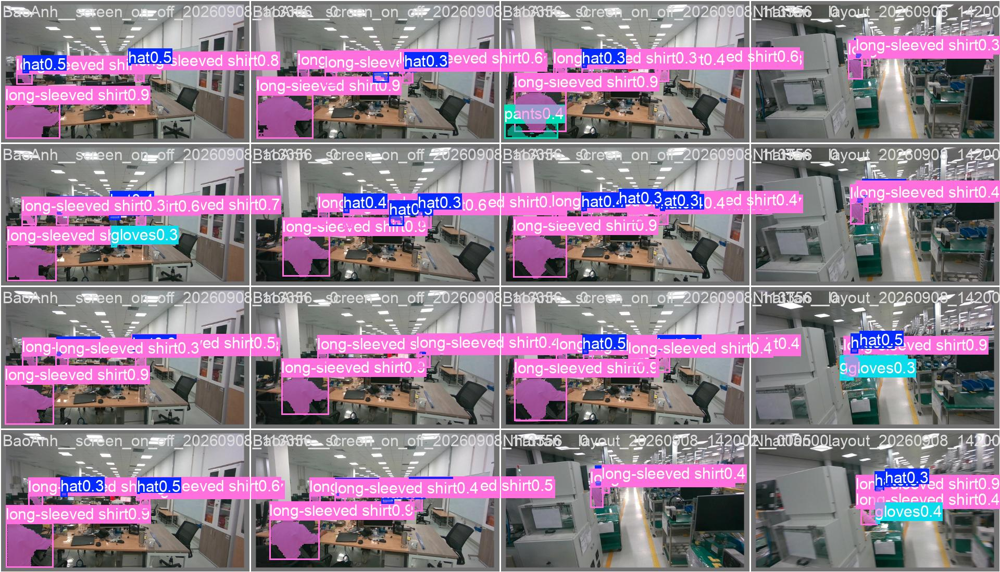

val_batch1_pred.jpg


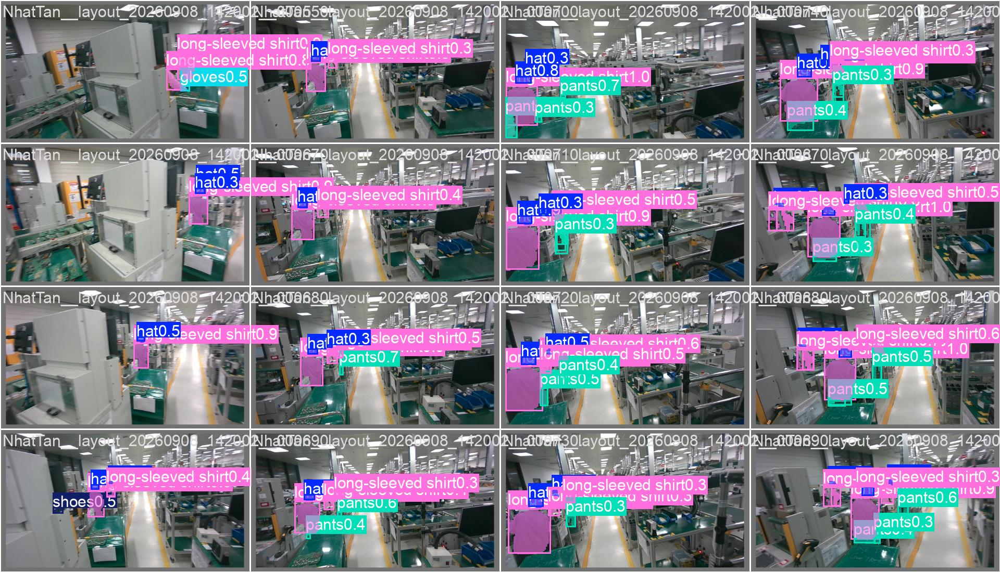

In [ ]:
from pathlib import Path
from IPython.display import display, Image as IPyImage

run_dir = Path(
    "/content/yolo11_seg_runs/yolo11s_seg_job54_job62"
)

print("Thu muc ket qua:", run_dir)

# 1. Bieu do qua trinh huan luyen
results_plot = run_dir / "results.png"

if results_plot.exists():
    print("\n1. TRAINING CURVES")
    display(IPyImage(filename=str(results_plot), width=1100))
else:
    print("Khong tim thay results.png")

# 2. Duong cong Precision-Recall cua mask
for name in ["MaskPR_curve.png", "MaskF1_curve.png",
             "MaskP_curve.png", "MaskR_curve.png"]:
    p = run_dir / name
    if p.exists():
        print("\n", name)
        display(IPyImage(filename=str(p), width=800))

# 3. So sanh nhan that va du doan tren validation
for pattern in ["val_batch*_labels.jpg", "val_batch*_pred.jpg"]:
    files = sorted(run_dir.glob(pattern))
    print(f"\n{pattern}: tim thay {len(files)} file")

    for p in files[:2]:
        print(p.name)
        display(IPyImage(filename=str(p), width=900))

In [ ]:
from pathlib import Path
import zipfile
import os

# ============================================================
# 1. DUONG DAN KET QUA HUAN LUYEN
# ============================================================

run_dir = Path(
    "/content/yolo11_seg_runs/yolo11s_seg_job54_job62"
)

if not run_dir.exists():
    raise FileNotFoundError(
        f"Khong tim thay thu muc ket qua: {run_dir}"
    )

best_pt = run_dir / "weights" / "best.pt"

if not best_pt.exists():
    raise FileNotFoundError(
        f"Khong tim thay checkpoint best.pt: {best_pt}"
    )

# ============================================================
# 2. DONG GOI OUTPUT THANH ZIP
# ============================================================

zip_path = Path("/content/yolo11s_seg_training_output.zip")

with zipfile.ZipFile(
    zip_path, "w", compression=zipfile.ZIP_DEFLATED
) as z:
    for file_path in run_dir.rglob("*"):
        if file_path.is_file():
            relative_path = file_path.relative_to(run_dir)
            archive_name = (
                Path("yolo11s_seg_job54_job62") / relative_path
            )
            z.write(file_path, arcname=str(archive_name))

    # Them cau hinh dataset de tham chieu
    data_yaml = Path("/content/yolo11_seg_dataset/data.yaml")
    if data_yaml.exists():
        z.write(data_yaml, arcname="dataset_data.yaml")

print("Da dong goi output.")
print(f"Dung luong ZIP: {zip_path.stat().st_size / 1024**2:.2f} MB")

print("\nDanh sach output chinh:")
with zipfile.ZipFile(zip_path, "r") as z:
    for name in z.namelist():
        print(" ", name)

# ============================================================
# 3. DANG NHAP GOOGLE VA UPLOAD LEN DRIVE
# ============================================================

from google.colab import auth
auth.authenticate_user()

from googleapiclient.discovery import build
from googleapiclient.http import MediaFileUpload

drive_service = build("drive", "v3")

file_metadata = {
    "name": "yolo11s_seg_training_output.zip",
    "mimeType": "application/zip",
}

media = MediaFileUpload(
    str(zip_path),
    mimetype="application/zip",
    resumable=True,
)

uploaded = drive_service.files().create(
    body=file_metadata,
    media_body=media,
    fields="id, name, size, webViewLink",
).execute()

file_id = uploaded["id"]

print("\nDa upload len Google Drive.")
print("Ten file:", uploaded["name"])
print("Dung luong:", round(int(uploaded.get("size", 0)) / 1024**2, 2), "MB")

# ============================================================
# 4. TAO LINK CHIA SE
# ============================================================

try:
    drive_service.permissions().create(
        fileId=file_id,
        body={
            "type": "anyone",
            "role": "reader",
        },
        fields="id",
    ).execute()

    file_info = drive_service.files().get(
        fileId=file_id,
        fields="id,name,webViewLink,size",
    ).execute()

    share_link = file_info.get(
        "webViewLink",
        f"https://drive.google.com/file/d/{file_id}/view",
    )

    print("\n" + "=" * 60)
    print("LINK CHIA SE OUTPUT:")
    print(share_link)
    print("=" * 60)

    print(
        "\nHay gui lai link tren cho toi. "
        "Nguoi co link co the xem/tai file theo quyen chia se."
    )

except Exception as e:
    print("\nFile da upload nhung khong tao duoc quyen chia se tu dong.")
    print("File ID:", file_id)
    print("Ly do:", str(e))
    print(
        "Mo Google Drive, tim file yolo11s_seg_training_output.zip, "
        "chon Share > General access > Anyone with the link > Viewer."
    )

Da dong goi output.
Dung luong ZIP: 485.48 MB

Danh sach output chinh:
  yolo11s_seg_job54_job62/MaskF1_curve.png
  yolo11s_seg_job54_job62/MaskR_curve.png
  yolo11s_seg_job54_job62/train_batch1.jpg
  yolo11s_seg_job54_job62/results.csv
  yolo11s_seg_job54_job62/results.png
  yolo11s_seg_job54_job62/confusion_matrix.png
  yolo11s_seg_job54_job62/MaskPR_curve.png
  yolo11s_seg_job54_job62/val_batch0_labels.jpg
  yolo11s_seg_job54_job62/MaskP_curve.png
  yolo11s_seg_job54_job62/args.yaml
  yolo11s_seg_job54_job62/BoxF1_curve.png
  yolo11s_seg_job54_job62/confusion_matrix_normalized.png
  yolo11s_seg_job54_job62/BoxPR_curve.png
  yolo11s_seg_job54_job62/val_batch0_pred.jpg
  yolo11s_seg_job54_job62/val_batch2_pred.jpg
  yolo11s_seg_job54_job62/BoxR_curve.png
  yolo11s_seg_job54_job62/val_batch1_pred.jpg
  yolo11s_seg_job54_job62/train_batch0.jpg
  yolo11s_seg_job54_job62/BoxP_curve.png
  yolo11s_seg_job54_job62/val_batch1_labels.jpg
  yolo11s_seg_job54_job62/val_batch2_labels.jpg
  yolo11


Da upload len Google Drive.
Ten file: yolo11s_seg_training_output.zip
Dung luong: 485.48 MB

LINK CHIA SE OUTPUT:
https://drive.google.com/file/d/13AghsUY6BLKJ-cHvD1H5UJ-LdKJPfvfS/view?usp=drivesdk

Hay gui lai link tren cho toi. Nguoi co link co the xem/tai file theo quyen chia se.


In [ ]:
from pathlib import Path
import zipfile
from google.colab import files

run_dir = Path(
    "/content/yolo11_seg_runs/yolo11s_seg_job54_job62"
)

if not run_dir.exists():
    raise FileNotFoundError(f"Khong tim thay: {run_dir}")

# Cac file quan trong cho viec phan tich training
selected_files = [
    "results.csv",
    "results.png",
    "args.yaml",
    "labels.jpg",
    "confusion_matrix.png",
    "confusion_matrix_normalized.png",
    "MaskPR_curve.png",
    "MaskF1_curve.png",
    "MaskP_curve.png",
    "MaskR_curve.png",
    "BoxPR_curve.png",
    "BoxF1_curve.png",
    "BoxP_curve.png",
    "BoxR_curve.png",
    "val_batch0_labels.jpg",
    "val_batch0_pred.jpg",
    "val_batch1_labels.jpg",
    "val_batch1_pred.jpg",
    "val_batch2_labels.jpg",
    "val_batch2_pred.jpg",
    "train_batch0.jpg",
    "train_batch1.jpg",
]

output_zip = Path("/content/yolo11s_seg_diagnostics.zip")
added = []

with zipfile.ZipFile(
    output_zip, "w", compression=zipfile.ZIP_DEFLATED
) as z:
    for name in selected_files:
        p = run_dir / name
        if p.is_file():
            z.write(p, arcname=name)
            added.append(name)

    # Them CSV neu co file ket qua khac
    for p in run_dir.glob("*.csv"):
        if p.name not in added:
            z.write(p, arcname=p.name)
            added.append(p.name)

print("So file duoc dong goi:", len(added))
print("Dung luong:", round(output_zip.stat().st_size / 1024**2, 2), "MB")
print("\nDanh sach file:")
for name in added:
    print(" -", name)

# Tai truc tiep ve may tinh
files.download(str(output_zip))

So file duoc dong goi: 22
Dung luong: 6.11 MB

Danh sach file:
 - results.csv
 - results.png
 - args.yaml
 - labels.jpg
 - confusion_matrix.png
 - confusion_matrix_normalized.png
 - MaskPR_curve.png
 - MaskF1_curve.png
 - MaskP_curve.png
 - MaskR_curve.png
 - BoxPR_curve.png
 - BoxF1_curve.png
 - BoxP_curve.png
 - BoxR_curve.png
 - val_batch0_labels.jpg
 - val_batch0_pred.jpg
 - val_batch1_labels.jpg
 - val_batch1_pred.jpg
 - val_batch2_labels.jpg
 - val_batch2_pred.jpg
 - train_batch0.jpg
 - train_batch1.jpg


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

So anh validation: 119
So phien quay: 3


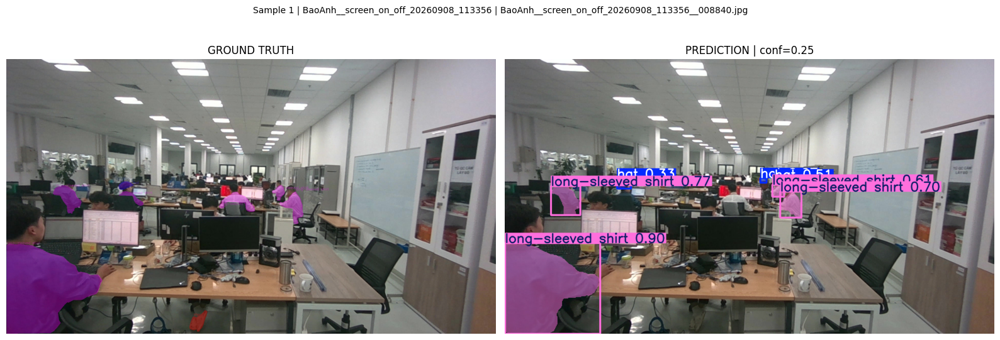

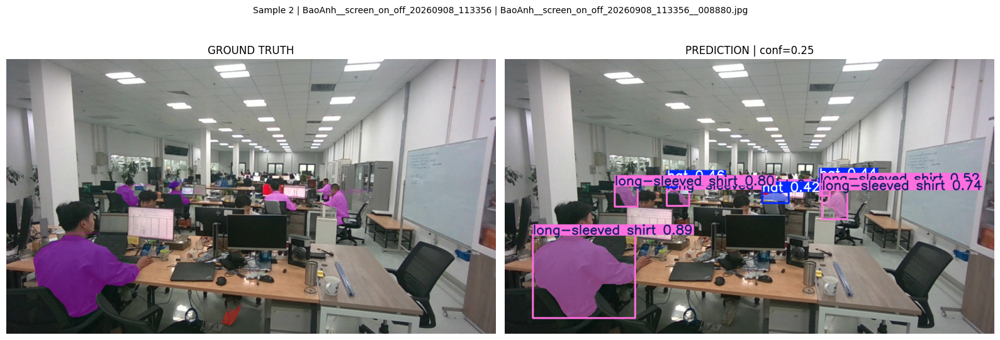

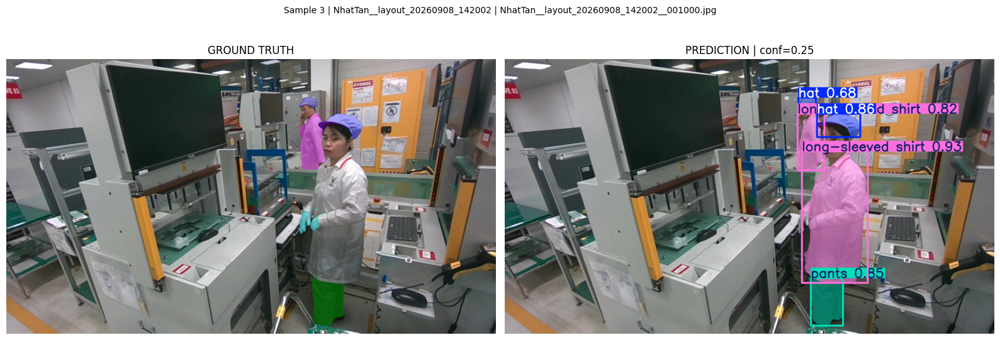

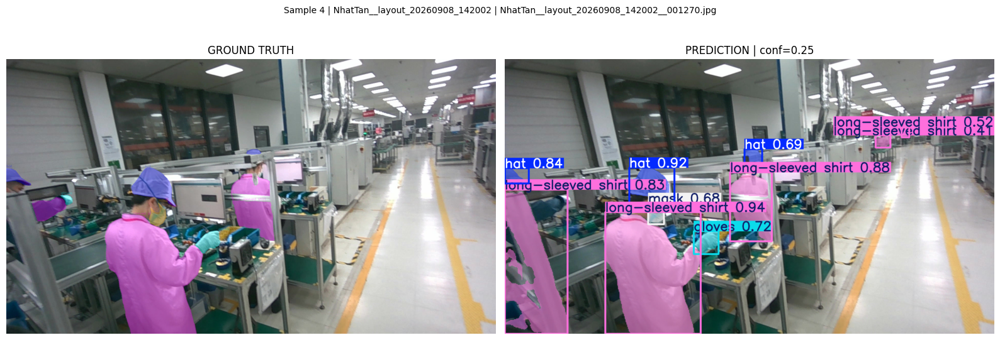

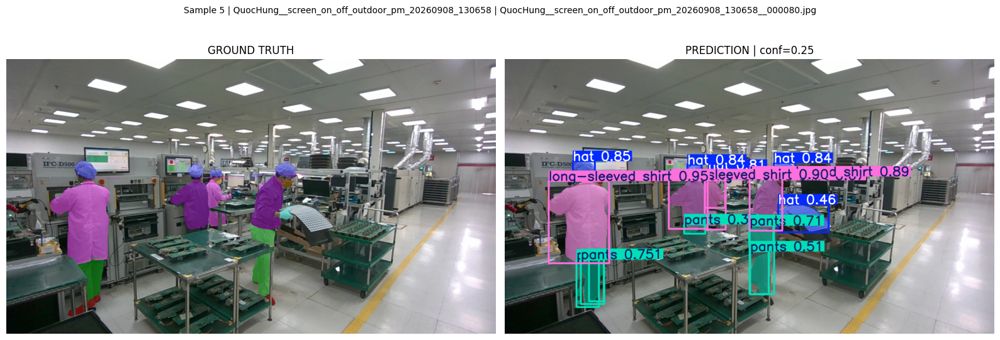

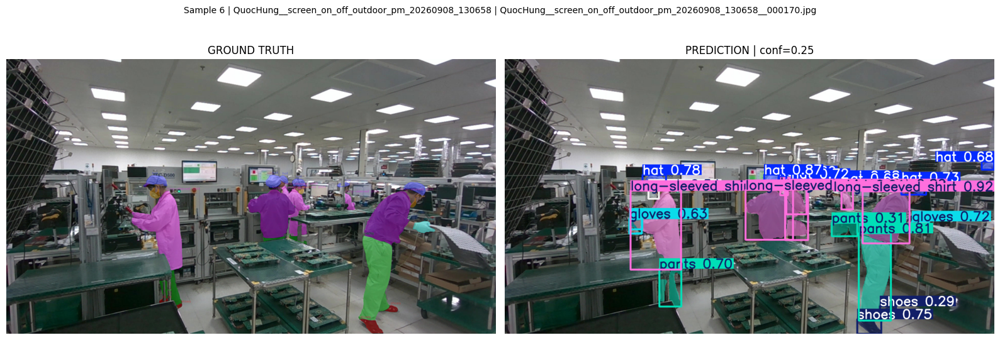

In [ ]:
from pathlib import Path, PurePosixPath
from collections import defaultdict
import cv2
import numpy as np
import matplotlib.pyplot as plt
from ultralytics import YOLO

# ---------------------------------------------------------
# 1. Duong dan
# ---------------------------------------------------------

DATASET = Path("/content/yolo11_seg_dataset")
WEIGHTS = Path(
    "/content/yolo11_seg_runs/yolo11s_seg_job54_job62/weights/best.pt"
)

if not WEIGHTS.exists():
    raise FileNotFoundError(
        "Khong tim thay best.pt trong runtime hien tai. "
        "Can upload lai checkpoint vao Colab truoc khi chay."
    )

model = YOLO(str(WEIGHTS))

CLASS_NAMES = {
    0: "hat",
    1: "gloves",
    2: "mask",
    3: "pants",
    4: "shoes",
    5: "long-sleeved shirt",
}

# Mau BGR theo class
COLORS = {
    0: (255, 0, 0),
    1: (255, 255, 0),
    2: (0, 165, 255),
    3: (0, 220, 0),
    4: (0, 0, 255),
    5: (255, 0, 255),
}


# ---------------------------------------------------------
# 2. Nhom anh theo phien quay
# ---------------------------------------------------------

def get_session(filename):
    stem = PurePosixPath(filename).stem
    parts = stem.rsplit("__", 1)

    if len(parts) == 2 and parts[1].isdigit():
        return parts[0]

    return stem


val_images = sorted(
    p for p in (DATASET / "images" / "val").iterdir()
    if p.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
)

groups = defaultdict(list)

for p in val_images:
    groups[get_session(p.name)].append(p)

print("So anh validation:", len(val_images))
print("So phien quay:", len(groups))

# Lay hai anh tu moi phien quay, neu co the
samples = []

for session, paths in sorted(groups.items()):
    paths = sorted(paths)
    positions = sorted(set([
        len(paths) // 3,
        (2 * len(paths)) // 3,
    ]))

    for idx in positions:
        samples.append((session, paths[idx]))


# ---------------------------------------------------------
# 3. Ve Ground Truth polygon
# ---------------------------------------------------------

def draw_ground_truth(image_path, label_path):
    image = cv2.imread(str(image_path))

    if image is None:
        raise RuntimeError(f"Khong doc duoc anh: {image_path}")

    h, w = image.shape[:2]
    overlay = image.copy()

    if label_path.exists():
        lines = label_path.read_text(
            encoding="utf-8-sig"
        ).splitlines()

        for line in lines:
            parts = line.split()
            if len(parts) < 7:
                continue

            cls = int(parts[0])
            coords = np.asarray(
                [float(v) for v in parts[1:]],
                dtype=np.float32
            ).reshape(-1, 2)

            points = np.round(
                coords * np.array([w, h])
            ).astype(np.int32)

            color = COLORS.get(cls, (255, 255, 255))

            cv2.fillPoly(overlay, [points], color)
            cv2.polylines(
                overlay, [points], True, color, 2
            )

            x, y = points[0]
            cv2.putText(
                overlay,
                CLASS_NAMES.get(cls, str(cls)),
                (int(x), max(15, int(y) - 5)),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.45,
                color,
                1,
                cv2.LINE_AA,
            )

    blended = cv2.addWeighted(image, 0.65, overlay, 0.35, 0)
    return cv2.cvtColor(blended, cv2.COLOR_BGR2RGB)


# ---------------------------------------------------------
# 4. In Ground Truth va Prediction rieng tung anh
# ---------------------------------------------------------

for i, (session, image_path) in enumerate(samples, start=1):
    label_path = (
        DATASET / "labels" / "val" / f"{image_path.stem}.txt"
    )

    gt_image = draw_ground_truth(image_path, label_path)

    result = model.predict(
        source=str(image_path),
        imgsz=640,
        conf=0.25,
        iou=0.70,
        device=0,
        verbose=False,
    )[0]

    pred_image = cv2.cvtColor(
        result.plot(
            labels=True,
            conf=True,
            boxes=True,
            masks=True,
        ),
        cv2.COLOR_BGR2RGB,
    )

    fig, axes = plt.subplots(1, 2, figsize=(16, 6))

    axes[0].imshow(gt_image)
    axes[0].set_title("GROUND TRUTH")
    axes[0].axis("off")

    axes[1].imshow(pred_image)
    axes[1].set_title("PREDICTION | conf=0.25")
    axes[1].axis("off")

    fig.suptitle(
        f"Sample {i} | {session} | {image_path.name}",
        fontsize=10
    )
    plt.tight_layout()
    plt.show()

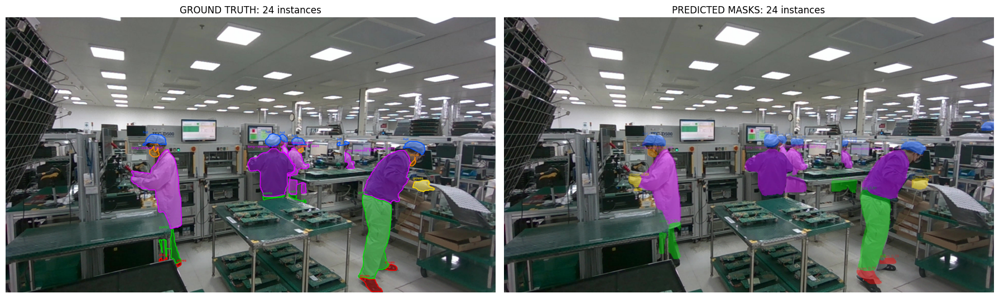


Ground truth instances: 24
Predicted instances: 24
Anh da luu: /content/mask_comparison_00170.png


In [ ]:
from pathlib import Path
import cv2
import numpy as np
import matplotlib.pyplot as plt
from ultralytics import YOLO

# -------------------------------------------------
# 1. Duong dan
# -------------------------------------------------

ROOT = Path("/content/yolo11_seg_dataset")

IMAGE_PATH = (
    ROOT / "images/val/"
    "QuocHung__screen_on_off_outdoor_pm_20260908_130658__000170.jpg"
)

LABEL_PATH = (
    ROOT / "labels/val/"
    "QuocHung__screen_on_off_outdoor_pm_20260908_130658__000170.txt"
)

WEIGHTS = Path(
    "/content/yolo11_seg_runs/yolo11s_seg_job54_job62/"
    "weights/best.pt"
)

for p in [IMAGE_PATH, LABEL_PATH, WEIGHTS]:
    if not p.exists():
        raise FileNotFoundError(f"Khong tim thay file: {p}")

CLASS_NAMES = {
    0: "hat",
    1: "gloves",
    2: "mask",
    3: "pants",
    4: "shoes",
    5: "long-sleeved shirt",
}

# Mau BGR, dung cung bang mau cho ground truth va prediction
COLORS = {
    0: (255, 80, 0),
    1: (0, 220, 255),
    2: (0, 140, 255),
    3: (0, 220, 0),
    4: (0, 0, 255),
    5: (255, 0, 220),
}

image = cv2.imread(str(IMAGE_PATH))
if image is None:
    raise RuntimeError("Khong doc duoc anh.")

h, w = image.shape[:2]
model = YOLO(str(WEIGHTS))


# -------------------------------------------------
# 2. Ve ground-truth mask tu polygon YOLO
# -------------------------------------------------

gt_overlay = image.copy()
gt_objects = []

for line_no, line in enumerate(
    LABEL_PATH.read_text(encoding="utf-8-sig").splitlines(),
    start=1
):
    parts = line.split()
    if not parts:
        continue

    cls = int(parts[0])
    coords = np.asarray(
        [float(x) for x in parts[1:]],
        dtype=np.float32
    )

    if cls not in CLASS_NAMES or len(coords) < 6 or len(coords) % 2:
        print(f"Bo qua dong label khong hop le: {line_no}")
        continue

    points = np.round(
        coords.reshape(-1, 2) * np.array([w, h])
    ).astype(np.int32)

    points[:, 0] = np.clip(points[:, 0], 0, w - 1)
    points[:, 1] = np.clip(points[:, 1], 0, h - 1)

    cv2.fillPoly(gt_overlay, [points], COLORS[cls])
    gt_objects.append((cls, points))


gt_view = cv2.addWeighted(image, 0.65, gt_overlay, 0.35, 0)

for cls, points in gt_objects:
    cv2.polylines(
        gt_view, [points], True, COLORS[cls], 2, cv2.LINE_AA
    )

    x_min = int(points[:, 0].min())
    y_min = int(points[:, 1].min())

    cv2.putText(
        gt_view,
        CLASS_NAMES[cls],
        (x_min, max(15, y_min - 4)),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.42,
        COLORS[cls],
        1,
        cv2.LINE_AA,
    )


# -------------------------------------------------
# 3. Du doan segmentation
# -------------------------------------------------

result = model.predict(
    source=str(IMAGE_PATH),
    imgsz=640,
    conf=0.25,
    iou=0.70,
    device=0,
    verbose=False,
)[0]

pred_view = image.copy()
pred_objects = []

if result.masks is not None and result.boxes is not None:
    mask_data = result.masks.data.cpu().numpy()
    class_ids = result.boxes.cls.cpu().numpy().astype(int)
    confidences = result.boxes.conf.cpu().numpy()

    for i in range(min(len(mask_data), len(class_ids))):
        cls = int(class_ids[i])
        if cls not in CLASS_NAMES:
            continue

        mask = mask_data[i]

        # Dua mask ve kich thuoc anh goc neu can
        if mask.shape != (h, w):
            mask = cv2.resize(
                mask.astype(np.float32),
                (w, h),
                interpolation=cv2.INTER_LINEAR,
            )

        binary_mask = mask > 0.5

        if not binary_mask.any():
            continue

        color = np.asarray(COLORS[cls], dtype=np.uint8)
        pred_view[binary_mask] = color

        contours, _ = cv2.findContours(
            binary_mask.astype(np.uint8),
            cv2.RETR_EXTERNAL,
            cv2.CHAIN_APPROX_SIMPLE,
        )

        cv2.drawContours(
            pred_view, contours, -1, COLORS[cls], 2, cv2.LINE_AA
        )

        ys, xs = np.where(binary_mask)
        x_min, y_min = int(xs.min()), int(ys.min())

        label = f"{CLASS_NAMES[cls]} {confidences[i]:.2f}"

        cv2.putText(
            pred_view,
            label,
            (x_min, max(15, y_min - 4)),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.42,
            COLORS[cls],
            1,
            cv2.LINE_AA,
        )

        pred_objects.append((cls, float(confidences[i])))
else:
    print("CANH BAO: Model khong tra ve mask nao cho anh nay.")


# Giu mot phan anh goc de nen anh con nhin thay ro
pred_view = cv2.addWeighted(image, 0.55, pred_view, 0.45, 0)


# -------------------------------------------------
# 4. Hien thi va luu anh
# -------------------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(18, 7))

axes[0].imshow(cv2.cvtColor(gt_view, cv2.COLOR_BGR2RGB))
axes[0].set_title(f"GROUND TRUTH: {len(gt_objects)} instances")
axes[0].axis("off")

axes[1].imshow(cv2.cvtColor(pred_view, cv2.COLOR_BGR2RGB))
axes[1].set_title(f"PREDICTED MASKS: {len(pred_objects)} instances")
axes[1].axis("off")

plt.tight_layout()

OUTPUT = "/content/mask_comparison_00170.png"
plt.savefig(OUTPUT, dpi=160, bbox_inches="tight")
plt.show()

print("\nGround truth instances:", len(gt_objects))
print("Predicted instances:", len(pred_objects))
print("Anh da luu:", OUTPUT)

In [ ]:
from ultralytics import YOLO
from pathlib import Path
import torch

DATA_YAML = "/content/yolo11_seg_dataset/data.yaml"
BEST_PT = (
    "/content/yolo11_seg_runs/yolo11s_seg_job54_job62/"
    "weights/best.pt"
)

assert Path(DATA_YAML).exists(), "Khong tim thay data.yaml"
assert Path(BEST_PT).exists(), "Khong tim thay best.pt"
assert torch.cuda.is_available(), "GPU CUDA chua san sang"

model = YOLO(BEST_PT)

print("Danh gia model voi imgsz=960...")
metrics = model.val(
    data=DATA_YAML,
    imgsz=960,
    batch=4,
    device=0,
    workers=2,
    plots=True,
    project="/content/yolo11_seg_runs",
    name="val_best_imgsz960",
    exist_ok=True,
)

print("\n===== KET QUA VALIDATION 960 =====")
print("Box mAP50:", metrics.box.map50)
print("Box mAP50-95:", metrics.box.map)
print("Mask mAP50:", metrics.seg.map50)
print("Mask mAP50-95:", metrics.seg.map)
print("\nThu muc ket qua:")
print("/content/yolo11_seg_runs/val_best_imgsz960")

Danh gia model voi imgsz=960...
Ultralytics 8.4.183 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11s-seg summary (fused): 113 layers, 10,069,138 parameters, 0 gradients, 32.9 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2300.1±384.9 MB/s, size: 359.8 KB)
val: Scanning /content/yolo11_seg_dataset/labels/val.cache... 119 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 119/119 8.1Mit/s 0.0s
val: /content/yolo11_seg_dataset/images/val/NhatTan__layout_20260908_142002__001090.jpg: 1 duplicate labels removed
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 30/30 3.8it/s 8.0s
                   all        119       1434        0.7      0.568       0.63      0.392      0.727      0.573      0.642      0.371
                   hat        117        365      0.789      0.762      0.821       0.55      0.798      0.756      0.826      0.511
                g

In [ ]:
from pathlib import Path
from collections import Counter

ROOT = Path("/content/yolo11_seg_dataset")

targets = [
    "NhatTan__layout_20260908_142002__001090",
]

for split in ["train", "val"]:
    label_dir = ROOT / "labels" / split

    for stem in targets:
        label_path = label_dir / f"{stem}.txt"

        if not label_path.exists():
            continue

        print("\n" + "=" * 65)
        print("FILE:", label_path)

        lines = [
            line.strip()
            for line in label_path.read_text(
                encoding="utf-8-sig"
            ).splitlines()
            if line.strip()
        ]

        counts = Counter(lines)
        duplicates = {
            line: count
            for line, count in counts.items()
            if count > 1
        }

        print("Tong so dong:", len(lines))
        print("So dong duy nhat:", len(counts))
        print("So dong bi lap:", sum(
            count - 1 for count in duplicates.values()
        ))

        if duplicates:
            print("\nCAC DONG TRUNG:")
            for line, count in duplicates.items():
                print(f"Lap {count} lan:")
                print(line[:500])
        else:
            print("Khong tim thay dong trung khop hoan toan.")


FILE: /content/yolo11_seg_dataset/labels/val/NhatTan__layout_20260908_142002__001090.txt
Tong so dong: 17
So dong duy nhat: 16
So dong bi lap: 1

CAC DONG TRUNG:
Lap 2 lan:
5 0.305458 0.415843 0.309109 0.453019 0.311010 0.452593 0.312781 0.451963 0.314661 0.452389 0.316562 0.453019 0.318219 0.454694 0.318573 0.458056 0.318089 0.461204 0.317865 0.464361 0.319266 0.466454 0.321172 0.467722 0.323417 0.468139 0.325292 0.468139 0.327078 0.467509 0.328615 0.465824 0.330151 0.463935 0.331094 0.461000 0.331094 0.457639 0.330266 0.454278 0.328969 0.451963 0.327667 0.448815 0.326594 0.445870 0.325646 0.442935 0.324594 0.439787 0.323885 0.436630 0.323062 0.433481 0.321760 0.4


In [ ]:
from pathlib import Path
from collections import Counter

ROOT = Path("/content/yolo11_seg_dataset")
LABEL_PATH = (
    ROOT / "labels/val/"
    "NhatTan__layout_20260908_142002__001090.txt"
)

assert LABEL_PATH.exists(), f"Khong tim thay: {LABEL_PATH}"

# Doc label, giu nguyen noi dung cac dong
original_text = LABEL_PATH.read_text(encoding="utf-8-sig")
lines = [
    line.strip()
    for line in original_text.splitlines()
    if line.strip()
]

counts = Counter(lines)
duplicate_lines = [
    line for line, count in counts.items()
    if count > 1
]

print("So dong ban dau:", len(lines))
print("So dong duy nhat:", len(counts))
print("So dong trung lap can loai:", sum(
    counts[line] - 1 for line in duplicate_lines
))

if not duplicate_lines:
    print("Khong con dong trung. Khong thay doi file.")
else:
    # Backup truoc khi chinh sua
    backup_path = LABEL_PATH.with_suffix(".txt.bak")
    backup_path.write_text(
        original_text,
        encoding="utf-8"
    )
    print("Da tao backup:", backup_path)

    # Giu lai mot ban cua moi dong, bao toan thu tu ban dau
    seen = set()
    cleaned_lines = []

    for line in lines:
        if line not in seen:
            cleaned_lines.append(line)
            seen.add(line)

    LABEL_PATH.write_text(
        "\n".join(cleaned_lines) + "\n",
        encoding="utf-8"
    )

    print("So dong sau khi sua:", len(cleaned_lines))
    print("So dong da loai:", len(lines) - len(cleaned_lines))

    # Kiem tra lai
    check_lines = [
        line.strip()
        for line in LABEL_PATH.read_text(encoding="utf-8").splitlines()
        if line.strip()
    ]

    assert len(check_lines) == len(set(check_lines)), (
        "Van con dong trung sau khi sua!"
    )

    # Xoa cache label de Ultralytics doc lai annotation moi
    for cache_path in (ROOT / "labels").glob("*.cache"):
        cache_path.unlink()
        print("Da xoa cache:", cache_path)

    print("\nKIEM TRA HOAN TAT: khong con dong label trung.")
    print("CVAT va ZIP goc khong bi thay doi.")

So dong ban dau: 17
So dong duy nhat: 16
So dong trung lap can loai: 1
Da tao backup: /content/yolo11_seg_dataset/labels/val/NhatTan__layout_20260908_142002__001090.txt.bak
So dong sau khi sua: 16
So dong da loai: 1
Da xoa cache: /content/yolo11_seg_dataset/labels/train.cache
Da xoa cache: /content/yolo11_seg_dataset/labels/val.cache

KIEM TRA HOAN TAT: khong con dong label trung.
CVAT va ZIP goc khong bi thay doi.


In [ ]:
import torch
import albumentations as A
from pathlib import Path
from ultralytics import YOLO

# ============================================================
# 1. KIEM TRA MODEL VA DATASET
# ============================================================

DATA_YAML = "/content/yolo11_seg_dataset/data.yaml"

INITIAL_WEIGHTS = (
    "/content/yolo11_seg_runs/yolo11s_seg_job54_job62/"
    "weights/best.pt"
)

assert Path(DATA_YAML).exists(), "Khong tim thay data.yaml"
assert Path(INITIAL_WEIGHTS).exists(), (
    "Khong tim thay best.pt cua lan train dau. "
    "Hay kiem tra Colab runtime."
)
assert torch.cuda.is_available(), "GPU CUDA chua san sang"

print("GPU:", torch.cuda.get_device_name(0))
print("Checkpoint khoi dau:", INITIAL_WEIGHTS)
print("Dataset:", DATA_YAML)

# ============================================================
# 2. AUGMENTATION BO SUNG
# ============================================================

custom_augmentations = [
    A.OneOf(
        [
            A.Blur(blur_limit=5, p=1.0),
            A.MotionBlur(blur_limit=5, p=1.0),
        ],
        p=0.12,
    ),
    A.RandomBrightnessContrast(
        brightness_limit=0.12,
        contrast_limit=0.12,
        p=0.20,
    ),
    A.GaussNoise(
        std_range=(0.01, 0.03),
        p=0.08,
    ),
]

# ============================================================
# 3. NAP CHECKPOINT TOT NHAT CUA LAN TRAIN DAU
# ============================================================

model = YOLO(INITIAL_WEIGHTS)

# ============================================================
# 4. FINE-TUNE
# ============================================================

results = model.train(
    data=DATA_YAML,

    # Do phan giai va batch phu hop GPU T4
    imgsz=960,
    batch=4,
    device=0,
    workers=2,

    # Fine-tune
    epochs=60,
    patience=20,
    optimizer="AdamW",
    lr0=0.001,
    lrf=0.01,
    warmup_epochs=2,
    weight_decay=0.0005,

    # On dinh ket qua
    seed=42,
    deterministic=True,
    amp=True,
    cache=False,

    # Augmentation hinh hoc
    fliplr=0.5,
    flipud=0.0,
    degrees=3.0,
    translate=0.08,
    scale=0.35,
    shear=0.0,
    perspective=0.0,

    # Augmentation mau sac
    hsv_h=0.015,
    hsv_s=0.40,
    hsv_v=0.25,

    # Mosaic vua phai
    mosaic=0.40,
    mixup=0.0,
    copy_paste=0.0,
    close_mosaic=10,

    # Blur, motion blur, contrast va noise
    augmentations=custom_augmentations,

    # Validation va luu checkpoint
    val=True,
    plots=True,
    save=True,
    save_period=10,

    # Tao thu muc rieng, khong ghi de lan train dau
    project="/content/yolo11_seg_runs",
    name="yolo11s_seg_finetune960",
    exist_ok=True,
)

print("\nFINE-TUNE HOAN TAT.")
print(
    "Best checkpoint:",
    "/content/yolo11_seg_runs/yolo11s_seg_finetune960/weights/best.pt"
)
print(
    "Last checkpoint:",
    "/content/yolo11_seg_runs/yolo11s_seg_finetune960/weights/last.pt"
)

GPU: Tesla T4
Checkpoint khoi dau: /content/yolo11_seg_runs/yolo11s_seg_job54_job62/weights/best.pt
Dataset: /content/yolo11_seg_dataset/data.yaml
Ultralytics 8.4.183 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, augmentations=[{'__version__': '2.0.8', 'transform': {'__class_fullname__': 'OneOf', 'p': 0.12, 'transforms': [{'__class_fullname__': 'Blur', 'p': 1.0, 'blur_limit': (3, 5)}, {'__class_fullname__': 'MotionBlur', 'p': 1.0, 'allow_shifted': True, 'angle_range': (0.0, 360.0), 'blur_limit': (3, 5), 'direction_range': (-1.0, 1.0)}]}}, {'__version__': '2.0.8', 'transform': {'__class_fullname__': 'RandomBrightnessContrast', 'p': 0.2, 'brightness_by_max': True, 'brightness_limit': (-0.12, 0.12), 'contrast_limit': (-0.12, 0.12), 'ensure_safe_range': False}}, {'__version__': '2.0.8', 'transform': {'__class_fullname__': 'GaussNoise', 'p': 0.08, 'mean_range': (0.0, 0.0), 'noise_scale_factor': 1.0, 'p

In [ ]:
from pathlib import Path
import zipfile

run_dir = Path(
    "/content/yolo11_seg_runs/yolo11s_seg_finetune960"
)

required = [
    run_dir / "weights" / "best.pt",
    run_dir / "weights" / "last.pt",
    run_dir / "results.csv",
    run_dir / "results.png",
    run_dir / "args.yaml",
]

for p in required:
    if not p.exists():
        raise FileNotFoundError(f"Khong tim thay: {p}")

output_zip = Path("/content/yolo11s_seg_finetune960_output.zip")

include_names = [
    "results.csv",
    "results.png",
    "args.yaml",
    "confusion_matrix.png",
    "confusion_matrix_normalized.png",
    "MaskPR_curve.png",
    "MaskF1_curve.png",
    "MaskP_curve.png",
    "MaskR_curve.png",
    "BoxPR_curve.png",
    "BoxF1_curve.png",
    "BoxP_curve.png",
    "BoxR_curve.png",
    "labels.jpg",
    "val_batch0_labels.jpg",
    "val_batch0_pred.jpg",
    "val_batch1_labels.jpg",
    "val_batch1_pred.jpg",
    "val_batch2_labels.jpg",
    "val_batch2_pred.jpg",
]

with zipfile.ZipFile(
    output_zip, "w", compression=zipfile.ZIP_DEFLATED
) as z:
    z.write(
        run_dir / "weights" / "best.pt",
        arcname="weights/best.pt"
    )
    z.write(
        run_dir / "weights" / "last.pt",
        arcname="weights/last.pt"
    )

    for name in include_names:
        p = run_dir / name
        if p.is_file():
            z.write(p, arcname=name)

    # Luu cau hinh dataset de tham chieu
    data_yaml = Path("/content/yolo11_seg_dataset/data.yaml")
    if data_yaml.exists():
        z.write(data_yaml, arcname="data.yaml")

print("Da tao:", output_zip)
print("Dung luong: %.2f MB" % (
    output_zip.stat().st_size / 1024**2
))

# Upload len Google Drive va tao link chia se
from google.colab import auth
auth.authenticate_user()

from googleapiclient.discovery import build
from googleapiclient.http import MediaFileUpload

drive_service = build("drive", "v3")

uploaded = drive_service.files().create(
    body={
        "name": "yolo11s_seg_finetune960_output.zip",
        "mimeType": "application/zip",
    },
    media_body=MediaFileUpload(
        str(output_zip),
        mimetype="application/zip",
        resumable=True,
    ),
    fields="id,name,size,webViewLink",
).execute()

file_id = uploaded["id"]

try:
    drive_service.permissions().create(
        fileId=file_id,
        body={"type": "anyone", "role": "reader"},
        fields="id",
    ).execute()

    link = drive_service.files().get(
        fileId=file_id,
        fields="webViewLink",
    ).execute()["webViewLink"]

    print("\nLINK CHIA SE MODEL FINE-TUNE:")
    print(link)

except Exception as e:
    print("\nFile da upload, nhung chua tao duoc quyen chia se.")
    print("File ID:", file_id)
    print("Hay mo Google Drive > Share > Anyone with the link > Viewer.")
    print("Chi tiet:", e)

Da tao: /content/yolo11s_seg_finetune960_output.zip
Dung luong: 40.29 MB



LINK CHIA SE MODEL FINE-TUNE:
https://drive.google.com/file/d/1GWHadycRDGFeVwe8Mh9YhIF4XcgOWbaz/view?usp=drivesdk


In [ ]:
from pathlib import Path
import zipfile
import os
import sys

# ============================================================
# 1. KHAI BAO DUONG DAN
# ============================================================

DATASET = Path("/content/yolo11_seg_dataset")

BASELINE = Path(
    "/content/yolo11_seg_runs/yolo11s_seg_job54_job62"
)

FINETUNE = Path(
    "/content/yolo11_seg_runs/yolo11s_seg_finetune960"
)

SOURCE_ZIPS = [
    Path("/content/job54.zip"),
    Path("/content/job62.zip"),
]

BACKUP = Path("/content/yolo11_seg_complete_backup.zip")
ROOT = "yolo11_seg_project_backup"

# Kiem tra cac thanh phan bat buoc
required = [
    DATASET / "images/train",
    DATASET / "images/val",
    DATASET / "labels/train",
    DATASET / "labels/val",
    FINETUNE / "weights/best.pt",
    FINETUNE / "weights/last.pt",
    FINETUNE / "results.csv",
]

for p in required:
    if not p.exists():
        raise FileNotFoundError(f"Khong tim thay: {p}")

for p in SOURCE_ZIPS:
    if not p.exists():
        raise FileNotFoundError(
            f"Thieu ZIP goc {p}. Hay upload lai ZIP nay vao /content "
            "truoc khi backup."
        )

print("Da tim thay dataset, checkpoint va hai ZIP goc.")

# ============================================================
# 2. TAO SCRIPT DE TIEP TUC FINE-TUNE SAU NAY
# ============================================================

continue_script = r'''
from pathlib import Path
import torch
import albumentations as A
from ultralytics import YOLO

ROOT = Path("/content/yolo11_seg_project_backup")

DATA_YAML = ROOT / "dataset" / "data.yaml"
BEST_PT = ROOT / "models" / "finetune_best.pt"

assert DATA_YAML.exists(), f"Missing dataset: {DATA_YAML}"
assert BEST_PT.exists(), f"Missing checkpoint: {BEST_PT}"
assert torch.cuda.is_available(), "Please enable GPU in Colab."

print("GPU:", torch.cuda.get_device_name(0))
print("Starting weights:", BEST_PT)
print("Dataset:", DATA_YAML)

# Moderate augmentations for clothing instance segmentation
custom_aug = [
    A.OneOf(
        [
            A.Blur(blur_limit=5, p=1.0),
            A.MotionBlur(blur_limit=5, p=1.0),
        ],
        p=0.12,
    ),
    A.RandomBrightnessContrast(
        brightness_limit=0.12,
        contrast_limit=0.12,
        p=0.20,
    ),
    A.GaussNoise(std_range=(0.01, 0.03), p=0.08),
]

# Start a NEW fine-tuning run from saved best weights.
# Do not use resume=True: optimizer state was stripped from
# the final checkpoint.
model = YOLO(str(BEST_PT))

results = model.train(
    data=str(DATA_YAML),
    imgsz=960,
    batch=4,
    device=0,
    workers=2,

    epochs=40,
    patience=15,
    optimizer="AdamW",
    lr0=0.0003,
    lrf=0.01,
    warmup_epochs=2,
    weight_decay=0.0005,

    seed=42,
    deterministic=True,
    amp=True,
    cache=False,

    fliplr=0.5,
    flipud=0.0,
    degrees=3.0,
    translate=0.08,
    scale=0.35,

    hsv_h=0.015,
    hsv_s=0.40,
    hsv_v=0.25,

    mosaic=0.40,
    mixup=0.0,
    copy_paste=0.0,
    close_mosaic=10,

    augmentations=custom_aug,

    val=True,
    plots=True,
    save=True,
    save_period=10,

    project="/content/yolo11_seg_runs",
    name="yolo11s_seg_home_finetune",
    exist_ok=True,
)

print("Training complete.")
print("Best checkpoint:")
print("/content/yolo11_seg_runs/yolo11s_seg_home_finetune/weights/best.pt")
'''

# ============================================================
# 3. README HUONG DAN KHOI PHUC
# ============================================================

readme = """
YOLO11-SEG PROJECT BACKUP
=========================

Dataset:
- Total images: 595
- Train: 476 images, 7 video sessions
- Validation: 119 images, 3 separate video sessions
- Classes:
  0 hat
  1 gloves
  2 mask
  3 pants
  4 shoes
  5 long-sleeved shirt

The prepared dataset contains the cleaned validation annotation.
One exact duplicate polygon was removed from:
NhatTan__layout_20260908_142002__001090.txt

The original job54.zip and job62.zip are also included unchanged.

MODEL CHECKPOINTS
=================
models/baseline_best.pt:
Initial YOLO11s-seg model.

models/finetune_best.pt:
Best checkpoint from fine-tuning at imgsz=960.

models/finetune_last.pt:
Last checkpoint from the fine-tuning run.

IMPORTANT:
The final checkpoints have their optimizer state stripped.
Use finetune_best.pt to start a NEW fine-tuning run.
This is not an exact optimizer-state resume of the previous run.

RECORDED VALIDATION METRICS
==========================
Baseline at imgsz=960:
Mask Precision: 0.727
Mask Recall:    0.573
Mask mAP50:     0.642
Mask mAP50-95:  0.371

Fine-tuned best checkpoint at imgsz=960:
Mask Precision: 0.808
Mask Recall:    0.635
Mask mAP50:     0.688
Mask mAP50-95:  0.408

These figures are from the existing validation split. They are not
a guarantee of performance on completely new recording sessions.

RESTORE IN GOOGLE COLAB
=======================
1. Enable a GPU runtime.
2. Upload this ZIP to /content, or copy it from mounted Google Drive.
3. Extract it into /content.
4. Install dependencies:
   pip install ultralytics albumentations
5. Run:
   python /content/yolo11_seg_project_backup/scripts/continue_training.py

The script starts a new fine-tuning run from finetune_best.pt.
It creates a separate output folder and does not overwrite this backup.
"""

# ============================================================
# 4. DONG GOI DU LIEU, MODEL, SCRIPT VA KET QUA
# ============================================================

image_exts = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
added_files = 0

def add_file(z, src, arcname):
    global added_files
    z.write(src, arcname=arcname)
    added_files += 1

with zipfile.ZipFile(
    BACKUP, "w", compression=zipfile.ZIP_DEFLATED
) as z:

    # Dataset images and labels. Only .txt labels are included:
    # this excludes .txt.bak and cache files.
    for split in ["train", "val"]:
        for p in sorted((DATASET / "images" / split).rglob("*")):
            if p.is_file() and p.suffix.lower() in image_exts:
                arc = f"{ROOT}/dataset/images/{split}/{p.relative_to(DATASET / 'images' / split)}"
                add_file(z, p, arc)

        for p in sorted((DATASET / "labels" / split).rglob("*.txt")):
            arc = f"{ROOT}/dataset/labels/{split}/{p.name}"
            add_file(z, p, arc)

    # Portable data.yaml pointing to the expected restore path
    yaml_text = f"""path: /content/{ROOT}/dataset
train: images/train
val: images/val
names:
  0: 'hat'
  1: 'gloves'
  2: 'mask'
  3: 'pants'
  4: 'shoes'
  5: 'long-sleeved shirt'
"""
    z.writestr(f"{ROOT}/dataset/data.yaml", yaml_text)

    # Checkpoints
    add_file(
        z, BASELINE / "weights" / "best.pt",
        f"{ROOT}/models/baseline_best.pt"
    )
    add_file(
        z, FINETUNE / "weights" / "best.pt",
        f"{ROOT}/models/finetune_best.pt"
    )
    add_file(
        z, FINETUNE / "weights" / "last.pt",
        f"{ROOT}/models/finetune_last.pt"
    )

    # Important run outputs from baseline and fine-tune
    for label, run_dir in [
        ("baseline", BASELINE),
        ("finetune960", FINETUNE),
    ]:
        for p in sorted(run_dir.iterdir()):
            if p.is_file() and p.suffix.lower() in {
                ".csv", ".png", ".jpg", ".yaml"
            }:
                add_file(
                    z, p,
                    f"{ROOT}/results/{label}/{p.name}"
                )

    # Original source ZIPs
    for p in SOURCE_ZIPS:
        add_file(z, p, f"{ROOT}/source_zips/{p.name}")

    z.writestr(f"{ROOT}/scripts/continue_training.py", continue_script)
    z.writestr(f"{ROOT}/README.txt", readme)

size_mb = BACKUP.stat().st_size / 1024**2

print("\nBackup archive created:")
print(BACKUP)
print(f"Size: {size_mb:.2f} MB")
print("Archived files:", added_files)

# ============================================================
# 5. UPLOAD BACKUP LEN GOOGLE DRIVE
# ============================================================

from google.colab import auth
auth.authenticate_user()

from googleapiclient.discovery import build
from googleapiclient.http import MediaFileUpload

drive_service = build("drive", "v3")

metadata = {
    "name": "yolo11_seg_complete_backup.zip",
    "mimeType": "application/zip",
}

media = MediaFileUpload(
    str(BACKUP),
    mimetype="application/zip",
    resumable=True,
    chunksize=8 * 1024 * 1024,
)

request = drive_service.files().create(
    body=metadata,
    media_body=media,
    fields="id,name,size,webViewLink",
)

response = None
while response is None:
    status, response = request.next_chunk()
    if status:
        print(f"Upload progress: {status.progress() * 100:.1f}%")

file_id = response["id"]

print("\nUpload completed.")
print("Name:", response["name"])
print("Size: %.2f MB" % (int(response.get("size", 0)) / 1024**2))

# Generate a share link
try:
    drive_service.permissions().create(
        fileId=file_id,
        body={"type": "anyone", "role": "reader"},
        fields="id",
    ).execute()

    info = drive_service.files().get(
        fileId=file_id,
        fields="webViewLink,name,size",
    ).execute()

    print("\n" + "=" * 65)
    print("FULL PROJECT BACKUP LINK:")
    print(info.get(
        "webViewLink",
        f"https://drive.google.com/file/d/{file_id}/view",
    ))
    print("=" * 65)
    print("Hay luu link nay de khoi phuc toan bo du an sau nay.")

except Exception as e:
    print("\nBackup da upload, nhung chua tao duoc quyen chia se tu dong.")
    print("File ID:", file_id)
    print("Google Drive > Share > General access > Anyone with the link.")
    print("Error:", str(e))

Da tim thay dataset, checkpoint va hai ZIP goc.

Backup archive created:
/content/yolo11_seg_complete_backup.zip
Size: 504.16 MB
Archived files: 1244


Upload progress: 1.6%
Upload progress: 3.2%
Upload progress: 4.8%
Upload progress: 6.3%
Upload progress: 7.9%
Upload progress: 9.5%
Upload progress: 11.1%
Upload progress: 12.7%
Upload progress: 14.3%
Upload progress: 15.9%
Upload progress: 17.5%
Upload progress: 19.0%
Upload progress: 20.6%
Upload progress: 22.2%
Upload progress: 23.8%
Upload progress: 25.4%
Upload progress: 27.0%
Upload progress: 28.6%
Upload progress: 30.1%
Upload progress: 31.7%
Upload progress: 33.3%
Upload progress: 34.9%
Upload progress: 36.5%
Upload progress: 38.1%
Upload progress: 39.7%
Upload progress: 41.3%
Upload progress: 42.8%
Upload progress: 44.4%
Upload progress: 46.0%
Upload progress: 47.6%
Upload progress: 49.2%
Upload progress: 50.8%
Upload progress: 52.4%
Upload progress: 54.0%
Upload progress: 55.5%
Upload progress: 57.1%
Upload progress: 58.7%
Upload progress: 60.3%
Upload progress: 61.9%
Upload progress: 63.5%
Upload progress: 65.1%
Upload progress: 66.6%
Upload progress: 68.2%
Upload progress: 

In [ ]:
# ============================================================
# KIỂM TRA ẢNH VÀ FILE NHÃN TRONG job54.zip, job62.zip
# Chạy nguyên cell này trong Google Colab.
# ============================================================

from pathlib import Path, PurePosixPath
from collections import defaultdict
import zipfile
import glob
import re
import os
import pandas as pd

# ------------------------------------------------------------
# 1. TÌM HAI FILE ZIP ĐÃ UPLOAD LÊN COLAB
# ------------------------------------------------------------

zip_files = glob.glob("/content/*.zip")

def find_zip(job_name):
    matches = [
        p for p in zip_files
        if Path(p).stem.lower().startswith(job_name.lower())
    ]

    if len(matches) == 0:
        raise FileNotFoundError(
            f"Không tìm thấy {job_name}.zip trong /content.\n"
            f"Các file ZIP hiện có: {[Path(p).name for p in zip_files]}\n"
            f"Hãy kiểm tra file đã được upload vào Colab chưa."
        )

    if len(matches) > 1:
        print(f"\nCó nhiều file bắt đầu bằng {job_name}:")
        for i, p in enumerate(matches):
            print(f"  [{i}] {p} ({os.path.getsize(p) / 1024**2:.2f} MB)")
        raise RuntimeError(
            f"Có nhiều bản {job_name}. Hãy chỉ định đúng đường dẫn "
            f"ở phần ZIP_PATHS để tránh kiểm tra nhầm bản export."
        )

    return matches[0]


ZIP_PATHS = {
    "job54": find_zip("job54"),
    "job62": find_zip("job62"),
}

print("=" * 80)
print("CÁC GÓI SẼ ĐƯỢC KIỂM TRA")
print("=" * 80)

for job, path in ZIP_PATHS.items():
    print(f"{job}: {path} ({os.path.getsize(path) / 1024**2:.2f} MB)")


# ------------------------------------------------------------
# 2. CÁC HÀM NHẬN DIỆN ẢNH, NHÃN VÀ FRAME
# ------------------------------------------------------------

IMAGE_EXTS = {
    ".jpg", ".jpeg", ".png", ".bmp",
    ".webp", ".tif", ".tiff"
}

def norm_stem(filename):
    """Chuẩn hóa tên gốc để so khớp ảnh với TXT."""
    return PurePosixPath(filename).stem.casefold()


def get_frame_info(filename):
    """
    Ví dụ:
      NhatTan__layout_20260908_142002__001290.jpg

    Kết quả:
      session = NhatTan__layout_20260908_142002
      frame   = 001290
    """
    stem = PurePosixPath(filename).stem
    m = re.search(r"__(\d+)$", stem)

    if m:
        frame = m.group(1)
        session = stem[:m.start()]
    else:
        frame = "KHÔNG TÁCH ĐƯỢC"
        session = stem

    return session, frame


def parse_label_text(text):
    """
    Kiểm tra cơ bản định dạng YOLO segmentation:
    mỗi dòng có class_id và ít nhất 3 điểm polygon
    (tức ít nhất 6 tọa độ x/y).
    """
    lines = [line.strip() for line in text.splitlines() if line.strip()]

    if not lines:
        return {
            "empty": True,
            "bad_lines": [],
            "duplicate_lines": [],
            "nonempty_rows": 0,
        }

    bad_lines = []
    seen = set()
    duplicate_lines = []

    for line_no, line in enumerate(lines, start=1):
        parts = line.split()

        valid = True

        # 1 class ID + tối thiểu 6 tọa độ
        if len(parts) < 7:
            valid = False
        else:
            try:
                class_id = int(parts[0])
                coords = [float(v) for v in parts[1:]]

                if class_id < 0:
                    valid = False
                if len(coords) < 6 or len(coords) % 2 != 0:
                    valid = False
            except ValueError:
                valid = False

        if not valid:
            bad_lines.append((line_no, line))

        # Tìm dòng polygon trùng nguyên văn sau khi chuẩn hóa khoảng trắng
        normalized_line = " ".join(line.split())
        if normalized_line in seen:
            duplicate_lines.append((line_no, normalized_line))
        else:
            seen.add(normalized_line)

    return {
        "empty": False,
        "bad_lines": bad_lines,
        "duplicate_lines": duplicate_lines,
        "nonempty_rows": len(lines),
    }


# ------------------------------------------------------------
# 3. QUÉT TỪNG ZIP VÀ ĐỐI CHIẾU ẢNH - NHÃN
# ------------------------------------------------------------

missing_label_rows = []
orphan_label_rows = []
empty_label_rows = []
malformed_label_rows = []
duplicate_polygon_rows = []
summary_rows = []

for job, zip_path in ZIP_PATHS.items():

    print("\n" + "=" * 80)
    print(f"ĐANG KIỂM TRA: {job} — {Path(zip_path).name}")
    print("=" * 80)

    with zipfile.ZipFile(zip_path, "r") as zf:
        all_files = [
            name for name in zf.namelist()
            if not name.endswith("/")
        ]

        # Chỉ lấy file ảnh, bỏ qua thư mục khác nếu có.
        image_paths = [
            name for name in all_files
            if PurePosixPath(name).suffix.lower() in IMAGE_EXTS
        ]

        # Chỉ lấy TXT trong thư mục labels.
        # Không nhầm train.txt hoặc các file TXT cấu hình là annotation.
        label_paths = [
            name for name in all_files
            if PurePosixPath(name).suffix.lower() == ".txt"
            and any(part.casefold() == "labels"
                    for part in PurePosixPath(name).parts)
        ]

        # Một stem có thể xuất hiện ở đường dẫn khác nhau, nên lưu thành list.
        images_by_stem = defaultdict(list)
        labels_by_stem = defaultdict(list)

        for p in image_paths:
            images_by_stem[norm_stem(p)].append(p)

        for p in label_paths:
            labels_by_stem[norm_stem(p)].append(p)

        image_stems = set(images_by_stem)
        label_stems = set(labels_by_stem)

        missing_stems = sorted(image_stems - label_stems)
        orphan_stems = sorted(label_stems - image_stems)

        print(f"Số file ảnh:                 {len(image_paths)}")
        print(f"Số file TXT trong labels/:   {len(label_paths)}")
        print(f"Số tên ảnh duy nhất:         {len(image_stems)}")
        print(f"Số tên nhãn duy nhất:        {len(label_stems)}")
        print(f"Ảnh không có TXT cùng tên:   {len(missing_stems)}")
        print(f"TXT không có ảnh cùng tên:   {len(orphan_stems)}")

        # 3A. Ảnh không có file TXT tương ứng
        for stem in missing_stems:
            for image_path in images_by_stem[stem]:
                session, frame = get_frame_info(image_path)

                row = {
                    "job_zip": Path(zip_path).name,
                    "loai_loi": "Ảnh không có TXT cùng tên",
                    "session": session,
                    "frame": frame,
                    "image": PurePosixPath(image_path).name,
                    "image_path_in_zip": image_path,
                    "label_path_in_zip": "",
                }

                missing_label_rows.append(row)

                print("\n[THIẾU FILE NHÃN]")
                print(f"  Gói ZIP : {Path(zip_path).name}")
                print(f"  Session : {session}")
                print(f"  Frame   : {frame}")
                print(f"  Ảnh     : {PurePosixPath(image_path).name}")
                print(f"  Đường dẫn ảnh: {image_path}")
                print(
                    "  Nhãn cần tìm: "
                    f"{PurePosixPath(image_path).stem}.txt"
                )

        # 3B. TXT không có ảnh cùng tên
        for stem in orphan_stems:
            for label_path in labels_by_stem[stem]:
                session, frame = get_frame_info(label_path)

                row = {
                    "job_zip": Path(zip_path).name,
                    "loai_loi": "TXT không có ảnh cùng tên",
                    "session": session,
                    "frame": frame,
                    "image": "",
                    "image_path_in_zip": "",
                    "label_path_in_zip": label_path,
                }

                orphan_label_rows.append(row)

                print("\n[FILE NHÃN KHÔNG CÓ ẢNH TƯƠNG ỨNG]")
                print(f"  Gói ZIP : {Path(zip_path).name}")
                print(f"  Session : {session}")
                print(f"  Frame   : {frame}")
                print(f"  TXT     : {label_path}")

        # 3C. Đọc nội dung tất cả TXT để tìm file rỗng,
        #     dòng polygon lỗi và polygon bị lặp chính xác.
        for label_path in label_paths:
            raw = zf.read(label_path)
            text = raw.decode("utf-8-sig", errors="replace")
            result = parse_label_text(text)

            session, frame = get_frame_info(label_path)
            corresponding_image = ""

            if norm_stem(label_path) in images_by_stem:
                corresponding_image = " | ".join(
                    PurePosixPath(p).name
                    for p in images_by_stem[norm_stem(label_path)]
                )

            if result["empty"]:
                empty_label_rows.append({
                    "job_zip": Path(zip_path).name,
                    "session": session,
                    "frame": frame,
                    "label": PurePosixPath(label_path).name,
                    "label_path_in_zip": label_path,
                    "image": corresponding_image,
                })

            for line_no, line in result["bad_lines"]:
                malformed_label_rows.append({
                    "job_zip": Path(zip_path).name,
                    "session": session,
                    "frame": frame,
                    "label": PurePosixPath(label_path).name,
                    "line": line_no,
                    "content": line,
                })

            for line_no, line in result["duplicate_lines"]:
                duplicate_polygon_rows.append({
                    "job_zip": Path(zip_path).name,
                    "session": session,
                    "frame": frame,
                    "label": PurePosixPath(label_path).name,
                    "line_trung": line_no,
                    "label_path_in_zip": label_path,
                })

        # 3D. In báo cáo file trùng tên gốc trong các đường dẫn khác nhau
        duplicate_image_stems = {
            stem: paths for stem, paths in images_by_stem.items()
            if len(paths) > 1
        }
        duplicate_label_stems = {
            stem: paths for stem, paths in labels_by_stem.items()
            if len(paths) > 1
        }

        print(f"\nStem ảnh bị trùng tên: {len(duplicate_image_stems)}")
        print(f"Stem TXT bị trùng tên:  {len(duplicate_label_stems)}")

        summary_rows.append({
            "job_zip": Path(zip_path).name,
            "images": len(image_paths),
            "label_txt": len(label_paths),
            "images_without_txt": len(missing_stems),
            "txt_without_image": len(orphan_stems),
            "empty_txt": sum(
                1 for p in label_paths
                if parse_label_text(
                    zf.read(p).decode("utf-8-sig", errors="replace")
                )["empty"]
            ),
        })


# ------------------------------------------------------------
# 4. IN BẢNG TỔNG HỢP TẤT CẢ CÁC LOẠI LỖI
# ------------------------------------------------------------

print("\n" + "#" * 80)
print("TỔNG HỢP CUỐI CÙNG")
print("#" * 80)

summary_df = pd.DataFrame(summary_rows)
display(summary_df)

def show_table(title, rows, columns=None):
    print(f"\n--- {title}: {len(rows)} ---")
    if rows:
        df = pd.DataFrame(rows)
        if columns:
            df = df[columns]
        display(df)
    else:
        print("Không phát hiện.")

show_table(
    "ẢNH KHÔNG CÓ FILE TXT CÙNG TÊN — CẦN KIỂM TRA ĐẦU TIÊN",
    missing_label_rows,
    ["job_zip", "session", "frame", "image", "image_path_in_zip"]
)

show_table(
    "TXT KHÔNG CÓ ẢNH TƯƠNG ỨNG",
    orphan_label_rows,
    ["job_zip", "session", "frame", "label_path_in_zip"]
)

show_table(
    "FILE TXT RỖNG / KHÔNG CÓ DÒNG NHÃN",
    empty_label_rows,
    ["job_zip", "session", "frame", "image", "label_path_in_zip"]
)

show_table(
    "DÒNG POLYGON SAI ĐỊNH DẠNG CƠ BẢN",
    malformed_label_rows,
    ["job_zip", "session", "frame", "label", "line", "content"]
)

show_table(
    "CÁC DÒNG POLYGON TRÙNG NGUYÊN VĂN",
    duplicate_polygon_rows,
    ["job_zip", "session", "frame", "label", "line_trung",
     "label_path_in_zip"]
)


# ------------------------------------------------------------
# 5. LƯU BÁO CÁO RA CSV ĐỂ TẢI VỀ NẾU CẦN
# ------------------------------------------------------------

out_dir = "/content/label_audit_report"
os.makedirs(out_dir, exist_ok=True)

pd.DataFrame(summary_rows).to_csv(
    f"{out_dir}/summary.csv", index=False, encoding="utf-8-sig"
)
pd.DataFrame(missing_label_rows).to_csv(
    f"{out_dir}/images_without_txt.csv", index=False, encoding="utf-8-sig"
)
pd.DataFrame(orphan_label_rows).to_csv(
    f"{out_dir}/txt_without_image.csv", index=False, encoding="utf-8-sig"
)
pd.DataFrame(empty_label_rows).to_csv(
    f"{out_dir}/empty_txt.csv", index=False, encoding="utf-8-sig"
)
pd.DataFrame(malformed_label_rows).to_csv(
    f"{out_dir}/malformed_polygons.csv", index=False, encoding="utf-8-sig"
)
pd.DataFrame(duplicate_polygon_rows).to_csv(
    f"{out_dir}/duplicate_polygon_rows.csv", index=False, encoding="utf-8-sig"
)

print("\nĐã lưu các bảng CSV tại:", out_dir)
print("Nếu muốn tải toàn bộ báo cáo, chạy cell kế tiếp:")
print("!zip -r /content/label_audit_report.zip /content/label_audit_report")

CÁC GÓI SẼ ĐƯỢC KIỂM TRA
job54: /content/job54.zip (110.10 MB)
job62: /content/job62.zip (114.56 MB)

ĐANG KIỂM TRA: job54 — job54.zip
Số file ảnh:                 297
Số file TXT trong labels/:   297
Số tên ảnh duy nhất:         297
Số tên nhãn duy nhất:        297
Ảnh không có TXT cùng tên:   0
TXT không có ảnh cùng tên:   0

Stem ảnh bị trùng tên: 0
Stem TXT bị trùng tên:  0

ĐANG KIỂM TRA: job62 — job62.zip
Số file ảnh:                 298
Số file TXT trong labels/:   298
Số tên ảnh duy nhất:         298
Số tên nhãn duy nhất:        298
Ảnh không có TXT cùng tên:   0
TXT không có ảnh cùng tên:   0

Stem ảnh bị trùng tên: 0
Stem TXT bị trùng tên:  0

################################################################################
TỔNG HỢP CUỐI CÙNG
################################################################################


,job_zip,images,label_txt,images_without_txt,txt_without_image,empty_txt
0,job54.zip,297,297,0,0,0
1,job62.zip,298,298,0,0,0



--- ẢNH KHÔNG CÓ FILE TXT CÙNG TÊN — CẦN KIỂM TRA ĐẦU TIÊN: 0 ---
Không phát hiện.

--- TXT KHÔNG CÓ ẢNH TƯƠNG ỨNG: 0 ---
Không phát hiện.

--- FILE TXT RỖNG / KHÔNG CÓ DÒNG NHÃN: 0 ---
Không phát hiện.

--- DÒNG POLYGON SAI ĐỊNH DẠNG CƠ BẢN: 0 ---
Không phát hiện.

--- CÁC DÒNG POLYGON TRÙNG NGUYÊN VĂN: 9 ---


,job_zip,session,frame,label,line_trung,label_path_in_zip
0,job54.zip,BaoAnh__screen_on_off_outdoor_pm_20260908_131056,000020,BaoAnh__screen_on_off_outdoor_pm_20260908_1310...,5,labels/train/batch_004/BaoAnh__screen_on_off_o...
1,job54.zip,BaoAnh__screen_on_off_outdoor_pm_20260908_131056,000020,BaoAnh__screen_on_off_outdoor_pm_20260908_1310...,6,labels/train/batch_004/BaoAnh__screen_on_off_o...
2,job54.zip,NhatTan__layout_20260908_142002,001090,NhatTan__layout_20260908_142002__001090.txt,4,labels/train/batch_004/NhatTan__layout_2026090...
3,job54.zip,BaoAnh__screen_on_off_outdoor_pm_20260908_131056,000030,BaoAnh__screen_on_off_outdoor_pm_20260908_1310...,6,labels/train/batch_004/BaoAnh__screen_on_off_o...
4,job54.zip,BaoAnh__screen_on_off_outdoor_pm_20260908_131056,000030,BaoAnh__screen_on_off_outdoor_pm_20260908_1310...,8,labels/train/batch_004/BaoAnh__screen_on_off_o...
5,job54.zip,BaoAnh__screen_on_off_outdoor_pm_20260908_131056,000030,BaoAnh__screen_on_off_outdoor_pm_20260908_1310...,10,labels/train/batch_004/BaoAnh__screen_on_off_o...
6,job54.zip,BaoAnh__screen_on_off_outdoor_pm_20260908_131056,000030,BaoAnh__screen_on_off_outdoor_pm_20260908_1310...,11,labels/train/batch_004/BaoAnh__screen_on_off_o...
7,job54.zip,BaoAnh__screen_on_off_outdoor_pm_20260908_131056,000030,BaoAnh__screen_on_off_outdoor_pm_20260908_1310...,12,labels/train/batch_004/BaoAnh__screen_on_off_o...
8,job54.zip,BaoAnh__screen_on_off_outdoor_pm_20260908_131056,000030,BaoAnh__screen_on_off_outdoor_pm_20260908_1310...,13,labels/train/batch_004/BaoAnh__screen_on_off_o...



Đã lưu các bảng CSV tại: /content/label_audit_report
Nếu muốn tải toàn bộ báo cáo, chạy cell kế tiếp:
!zip -r /content/label_audit_report.zip /content/label_audit_report


In [ ]:
from pathlib import Path, PurePosixPath
from collections import defaultdict
import zipfile
import glob
import re
import os
import pandas as pd
from IPython.display import display

# ============================================================
# 1. TÌM ZIP
# ============================================================

def locate_zip(job_name):
    candidates = glob.glob(f"/content/{job_name}.zip")

    if candidates:
        return candidates[0]

    candidates = [
        p for p in glob.glob("/content/*.zip")
        if Path(p).stem.lower().startswith(job_name.lower())
    ]

    if len(candidates) == 1:
        return candidates[0]

    if len(candidates) == 0:
        raise FileNotFoundError(
            f"Không tìm thấy {job_name}.zip trong /content. "
            "Hãy kiểm tra lại file đã upload lên Colab chưa."
        )

    raise RuntimeError(
        f"Có nhiều ZIP cho {job_name}: {candidates}. "
        "Hãy chỉ định đúng đường dẫn thủ công."
    )

ZIP_PATHS = {
    "job54": locate_zip("job54"),
    "job62": locate_zip("job62"),
}

IMAGE_EXTS = {
    ".jpg", ".jpeg", ".png", ".bmp",
    ".webp", ".tif", ".tiff"
}

def clean_path(path):
    return str(path).strip().strip('"').strip("'").replace("\\", "/")

def stem_of(path):
    return PurePosixPath(clean_path(path)).stem.casefold()

def get_session_and_frame(path):
    stem = PurePosixPath(clean_path(path)).stem
    match = re.search(r"__(\d+)$", stem)

    if match:
        return stem[:match.start()], match.group(1)

    return stem, "Không tách được từ tên file"


# ============================================================
# 2. KIỂM TRA TỪNG ZIP
# ============================================================

missing_rows = []
summary_rows = []

for job_name, zip_path in ZIP_PATHS.items():
    print("\n" + "=" * 100)
    print(f"ĐANG KIỂM TRA {job_name.upper()}: {Path(zip_path).name}")
    print("=" * 100)

    with zipfile.ZipFile(zip_path, "r") as zf:
        members = [
            name for name in zf.namelist()
            if not name.endswith("/")
        ]

        # Tất cả ảnh trong ZIP
        image_paths = [
            name for name in members
            if PurePosixPath(name).suffix.lower() in IMAGE_EXTS
        ]

        # TXT annotation trong thư mục labels/
        label_paths = [
            name for name in members
            if PurePosixPath(name).suffix.lower() == ".txt"
            and any(
                part.casefold() == "labels"
                for part in PurePosixPath(name).parts
            )
        ]

        image_by_stem = defaultdict(list)
        label_by_stem = defaultdict(list)

        for p in image_paths:
            image_by_stem[stem_of(p)].append(p)

        for p in label_paths:
            label_by_stem[stem_of(p)].append(p)

        # ----------------------------------------------------
        # Đọc danh sách ảnh: train.txt, val.txt, test.txt...
        # Lưu cả dòng vật lý và thứ tự ảnh không rỗng.
        # ----------------------------------------------------

        list_files = [
            name for name in members
            if PurePosixPath(name).name.lower()
            in {"train.txt", "val.txt", "test.txt"}
            and not any(
                part.casefold() == "labels"
                for part in PurePosixPath(name).parts
            )
        ]

        # stem -> vị trí ảnh trong file danh sách
        list_lookup = defaultdict(list)

        for list_file in list_files:
            raw = zf.read(list_file).decode(
                "utf-8-sig", errors="replace"
            )

            image_entry_index = 0

            for physical_line_no, raw_line in enumerate(
                raw.splitlines(), start=1
            ):
                line = clean_path(raw_line)

                if not line or line.startswith("#"):
                    continue

                # Chỉ xét những dòng trông như đường dẫn ảnh.
                if PurePosixPath(line).suffix.lower() not in IMAGE_EXTS:
                    continue

                image_entry_index += 1

                list_lookup[stem_of(line)].append({
                    "list_file": list_file,
                    "list_line": physical_line_no,
                    "image_entry_index": image_entry_index,
                    "listed_path": line,
                })

        # ----------------------------------------------------
        # Tìm ảnh có tồn tại nhưng không có TXT cùng stem
        # ----------------------------------------------------

        missing_stems = sorted(
            set(image_by_stem) - set(label_by_stem)
        )

        print(f"Số ảnh trong ZIP:                 {len(image_paths)}")
        print(f"Số file TXT nằm trong labels/:    {len(label_paths)}")
        print(f"Số ảnh không có TXT cùng tên:     {len(missing_stems)}")
        print(f"Số file danh sách ảnh tìm thấy:   {len(list_files)}")

        if not list_files:
            print(
                "\nCẢNH BÁO: Không tìm thấy train.txt/val.txt/test.txt. "
                "Cell vẫn kiểm tra được ảnh thiếu TXT, nhưng không có số "
                "dòng danh sách để đối chiếu."
            )

        for missing_stem in missing_stems:
            for image_path in image_by_stem[missing_stem]:
                session, frame_suffix = get_session_and_frame(image_path)
                positions = list_lookup.get(missing_stem, [])

                if not positions:
                    missing_rows.append({
                        "job": job_name,
                        "zip": Path(zip_path).name,
                        "session": session,
                        "frame_suffix_filename": frame_suffix,
                        "list_file": "Không tìm thấy ảnh trong train/val/test.txt",
                        "list_line_number": None,
                        "image_entry_index": None,
                        "image_filename": PurePosixPath(image_path).name,
                        "image_path_in_zip": image_path,
                        "expected_label": PurePosixPath(image_path).stem + ".txt",
                        "label_exists": False,
                    })

                else:
                    for pos in positions:
                        missing_rows.append({
                            "job": job_name,
                            "zip": Path(zip_path).name,
                            "session": session,
                            "frame_suffix_filename": frame_suffix,
                            "list_file": pos["list_file"],
                            "list_line_number": pos["list_line"],
                            "image_entry_index": pos["image_entry_index"],
                            "image_filename": PurePosixPath(image_path).name,
                            "image_path_in_zip": image_path,
                            "listed_path_in_txt": pos["listed_path"],
                            "expected_label": PurePosixPath(image_path).stem + ".txt",
                            "label_exists": False,
                        })

        summary_rows.append({
            "job": job_name,
            "zip": Path(zip_path).name,
            "images": len(image_paths),
            "label_txt": len(label_paths),
            "images_missing_txt": len(missing_stems),
            "list_files": ", ".join(
                PurePosixPath(x).name for x in list_files
            ),
        })


# ============================================================
# 3. IN BẢNG CHI TIẾT CÓ SỐ DÒNG
# ============================================================

print("\n" + "#" * 100)
print("KẾT QUẢ CHÍNH: ẢNH THIẾU NHÃN VÀ DÒNG TƯƠNG ỨNG TRONG FILE TXT")
print("#" * 100)

summary_df = pd.DataFrame(summary_rows)
display(summary_df)

missing_df = pd.DataFrame(missing_rows)

if missing_df.empty:
    print("Không tìm thấy ảnh thiếu TXT trong hai ZIP.")
else:
    # Ưu tiên các cột giúp tìm ảnh trong CVAT
    cols = [
        "job",
        "session",
        "frame_suffix_filename",
        "list_file",
        "list_line_number",
        "image_entry_index",
        "image_filename",
        "image_path_in_zip",
        "listed_path_in_txt",
        "expected_label",
    ]

    cols = [c for c in cols if c in missing_df.columns]

    display(missing_df[cols])

    print("\n" + "=" * 100)
    print("TỪNG ẢNH THIẾU NHÃN — IN RIÊNG ĐỂ DỄ TRA CVAT")
    print("=" * 100)

    for _, row in missing_df.iterrows():
        print(f"\nJOB: {row['job']}  |  ZIP: {row['zip']}")
        print(f"Phiên ghi hình: {row['session']}")
        print(f"Hậu tố frame trong tên ảnh: {row['frame_suffix_filename']}")
        print(f"File danh sách: {row['list_file']}")
        print(f"Số thứ tự dòng thực tế: {row['list_line_number']}")
        print(f"Số thứ tự ảnh không rỗng trong danh sách: {row['image_entry_index']}")
        print(f"Tên ảnh: {row['image_filename']}")
        print(f"Đường dẫn ảnh trong ZIP: {row['image_path_in_zip']}")
        print(f"TXT tương ứng đang thiếu: {row['expected_label']}")

# ============================================================
# 4. LƯU KẾT QUẢ ĐỂ TẢI VỀ
# ============================================================

out_dir = "/content/frame_label_audit"
os.makedirs(out_dir, exist_ok=True)

summary_df.to_csv(
    f"{out_dir}/summary.csv",
    index=False,
    encoding="utf-8-sig"
)

missing_df.to_csv(
    f"{out_dir}/missing_frames_with_line_numbers.csv",
    index=False,
    encoding="utf-8-sig"
)

print("\nĐã lưu báo cáo:")
print(f"{out_dir}/summary.csv")
print(f"{out_dir}/missing_frames_with_line_numbers.csv")
print("\nBạn có thể tải CSV từ bảng Files bên trái trong Colab.")


ĐANG KIỂM TRA JOB54: job54.zip
Số ảnh trong ZIP:                 297
Số file TXT nằm trong labels/:    297
Số ảnh không có TXT cùng tên:     0
Số file danh sách ảnh tìm thấy:   1

ĐANG KIỂM TRA JOB62: job62.zip
Số ảnh trong ZIP:                 298
Số file TXT nằm trong labels/:    298
Số ảnh không có TXT cùng tên:     0
Số file danh sách ảnh tìm thấy:   1

####################################################################################################
KẾT QUẢ CHÍNH: ẢNH THIẾU NHÃN VÀ DÒNG TƯƠNG ỨNG TRONG FILE TXT
####################################################################################################


,job,zip,images,label_txt,images_missing_txt,list_files
0,job54,job54.zip,297,297,0,train.txt
1,job62,job62.zip,298,298,0,train.txt


Không tìm thấy ảnh thiếu TXT trong hai ZIP.

Đã lưu báo cáo:
/content/frame_label_audit/summary.csv
/content/frame_label_audit/missing_frames_with_line_numbers.csv

Bạn có thể tải CSV từ bảng Files bên trái trong Colab.


In [ ]:
from pathlib import Path, PurePosixPath
import glob
import zipfile
import re

TARGET_LABEL = "NhatTan__layout_20260908_142002__001090.txt"
TARGET_STEM = Path(TARGET_LABEL).stem

IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp", ".tif", ".tiff"}

# Tìm ZIP đã upload trong /content
zip_files = glob.glob("/content/**/*.zip", recursive=True)
zip_files = sorted(set(zip_files))

if not zip_files:
    raise FileNotFoundError("Không tìm thấy file ZIP nào trong /content.")

found_any = False

for zip_path in zip_files:
    zip_name = Path(zip_path).name

    # Chỉ kiểm tra hai gói dữ liệu CVAT
    if not (
        zip_name.lower().startswith("job54")
        or zip_name.lower().startswith("job62")
    ):
        continue

    with zipfile.ZipFile(zip_path, "r") as zf:
        members = [
            name for name in zf.namelist()
            if not name.endswith("/")
        ]

        # Tìm file TXT theo tên chính xác trong labels/val/
        matching_labels = [
            name for name in members
            if PurePosixPath(name).name == TARGET_LABEL
            and "labels" in [
                part.lower() for part in PurePosixPath(name).parts
            ]
            and "val" in [
                part.lower() for part in PurePosixPath(name).parts
            ]
        ]

        if not matching_labels:
            continue

        found_any = True

        for label_path in matching_labels:
            label_stem = PurePosixPath(label_path).stem

            # Tách tên phiên ghi hình và số frame ở cuối tên
            match = re.search(r"__(\d+)$", label_stem)

            if match:
                frame_suffix = match.group(1)
                session_name = label_stem[:match.start()]
            else:
                frame_suffix = "Không tách được"
                session_name = label_stem

            print("\n" + "=" * 75)
            print("ĐÃ TÌM THẤY FILE NHÃN")
            print("=" * 75)
            print(f"ZIP / job        : {zip_name}")
            print(f"Split            : val")
            print(f"Đường dẫn nhãn   : {label_path}")
            print(f"Phiên ghi hình   : {session_name}")
            print(f"Frame suffix     : {frame_suffix}")
            print(f"Tên ảnh dự kiến  : {label_stem}.jpg")

            # Tìm ảnh có cùng tên gốc, không phụ thuộc phần mở rộng
            matching_images = [
                name for name in members
                if PurePosixPath(name).suffix.lower() in IMAGE_EXTS
                and PurePosixPath(name).stem == label_stem
            ]

            if matching_images:
                print("\nẢnh tương ứng tìm được:")
                for image_path in matching_images:
                    print(f"  {image_path}")
            else:
                print("\nCẢNH BÁO: Không tìm thấy ảnh cùng tên trong ZIP này.")

            # Tìm ảnh trong val.txt để xác định vị trí dòng danh sách
            list_files = [
                name for name in members
                if PurePosixPath(name).name.lower() == "val.txt"
                and "labels" not in [
                    part.lower() for part in PurePosixPath(name).parts
                ]
            ]

            list_found = False

            for list_path in list_files:
                content = zf.read(list_path).decode(
                    "utf-8-sig", errors="replace"
                )

                for physical_line, line in enumerate(
                    content.splitlines(), start=1
                ):
                    entry = line.strip().replace("\\", "/")

                    if entry and Path(entry).stem == label_stem:
                        list_found = True
                        print(f"\nFile danh sách    : {list_path}")
                        print(f"Số thứ tự dòng    : {physical_line}")
                        print(f"Nội dung dòng     : {entry}")

            if not list_found:
                print(
                    "\nKhông tìm thấy tên ảnh trong val.txt của ZIP này "
                    "(hoặc ZIP không chứa val.txt)."
                )

if not found_any:
    print(
        f"KHÔNG TÌM THẤY {TARGET_LABEL} "
        "trong labels/val/ của job54.zip hoặc job62.zip."
    )

KHÔNG TÌM THẤY NhatTan__layout_20260908_142002__001090.txt trong labels/val/ của job54.zip hoặc job62.zip.


In [ ]:
from pathlib import Path, PurePosixPath
import glob
import zipfile
import re

TARGET_STEM = "NhatTan__layout_20260908_142002__001090"

IMAGE_EXTS = {
    ".jpg", ".jpeg", ".png", ".bmp",
    ".webp", ".tif", ".tiff"
}

# Tìm tất cả ZIP trong /content và thư mục con
all_zips = glob.glob("/content/**/*.zip", recursive=True)

zip_paths = [
    p for p in all_zips
    if Path(p).name.lower().startswith(("job54", "job62"))
]

if not zip_paths:
    raise FileNotFoundError(
        "Không tìm thấy job54.zip hoặc job62.zip trong /content. "
        "Hãy kiểm tra tên file trong Colab."
    )

found_anywhere = False

for zip_path in sorted(zip_paths):
    zip_name = Path(zip_path).name

    print("\n" + "=" * 90)
    print(f"KIỂM TRA: {zip_name}")
    print("=" * 90)

    with zipfile.ZipFile(zip_path, "r") as zf:
        members = [
            name for name in zf.namelist()
            if not name.endswith("/")
        ]

        # Tìm đúng tên gốc trong TẤT CẢ thư mục, không giả định train/val.
        exact_matches = [
            name for name in members
            if PurePosixPath(name).stem.casefold()
            == TARGET_STEM.casefold()
        ]

        if exact_matches:
            found_anywhere = True

            for path in exact_matches:
                filename = PurePosixPath(path).name
                ext = PurePosixPath(path).suffix.lower()

                print("\nĐÃ TÌM THẤY:")
                print(f"  ZIP             : {zip_name}")
                print(f"  Đường dẫn trong ZIP: {path}")
                print(f"  Tên file        : {filename}")

                if ext in IMAGE_EXTS:
                    print("  Loại file       : ẢNH")
                elif ext == ".txt":
                    print("  Loại file       : FILE NHÃN TXT")
                else:
                    print(f"  Loại file       : {ext or 'không có phần mở rộng'}")

                # Tách session và hậu tố frame từ tên.
                match = re.search(r"__(\d+)$", TARGET_STEM)

                if match:
                    print(f"  Phiên ghi hình  : {TARGET_STEM[:match.start()]}")
                    print(f"  Frame suffix    : {match.group(1)}")

        else:
            print("Không có file trùng chính xác tên này trong ZIP.")

        # Tìm dòng trong train.txt, val.txt hoặc danh sách ảnh khác,
        # nếu danh sách có lưu đường dẫn ảnh theo stem này.
        list_files = [
            name for name in members
            if PurePosixPath(name).suffix.lower() == ".txt"
            and PurePosixPath(name).name.lower()
            in {"train.txt", "val.txt", "test.txt"}
        ]

        list_match_found = False

        for list_path in list_files:
            content = zf.read(list_path).decode(
                "utf-8-sig", errors="replace"
            )

            image_index = 0

            for physical_line_no, line in enumerate(
                content.splitlines(), start=1
            ):
                entry = line.strip().replace("\\", "/")

                if not entry or entry.startswith("#"):
                    continue

                if PurePosixPath(entry).suffix.lower() in IMAGE_EXTS:
                    image_index += 1

                if PurePosixPath(entry).stem.casefold() == TARGET_STEM.casefold():
                    list_match_found = True
                    found_anywhere = True

                    print("\nCÓ TRONG FILE DANH SÁCH:")
                    print(f"  Danh sách       : {list_path}")
                    print(f"  Số dòng thực tế : {physical_line_no}")
                    print(f"  Thứ tự ảnh      : {image_index}")
                    print(f"  Nội dung dòng   : {entry}")

        if not list_match_found:
            print(
                "\nKhông thấy tên này trong train.txt/val.txt/test.txt "
                "của ZIP (nếu các file danh sách tồn tại)."
            )

        # Nếu không tìm thấy đúng tên, in các frame gần đó của cùng session.
        if not exact_matches:
            prefix = "NhatTan__layout_20260908_142002__"

            nearby = []
            for path in members:
                stem = PurePosixPath(path).stem

                if stem.startswith(prefix):
                    suffix = stem[len(prefix):]
                    if suffix.isdigit():
                        frame_no = int(suffix)
                        if abs(frame_no - 1090) <= 30:
                            nearby.append((frame_no, path))

            if nearby:
                print("\nCác file cùng session, trong khoảng frame 001060–001120:")
                for frame_no, path in sorted(set(nearby)):
                    print(f"  Frame {frame_no:06d}: {path}")

if not found_anywhere:
    print("\nKhông tìm thấy tên này trong hai ZIP hoặc các danh sách ảnh.")
    print("Hãy gửi lại phần output trên để kiểm tra tên file thực tế.")


KIỂM TRA: job54.zip

ĐÃ TÌM THẤY:
  ZIP             : job54.zip
  Đường dẫn trong ZIP: labels/train/batch_004/NhatTan__layout_20260908_142002__001090.txt
  Tên file        : NhatTan__layout_20260908_142002__001090.txt
  Loại file       : FILE NHÃN TXT
  Phiên ghi hình  : NhatTan__layout_20260908_142002
  Frame suffix    : 001090

ĐÃ TÌM THẤY:
  ZIP             : job54.zip
  Đường dẫn trong ZIP: images/train/batch_004/NhatTan__layout_20260908_142002__001090.jpg
  Tên file        : NhatTan__layout_20260908_142002__001090.jpg
  Loại file       : ẢNH
  Phiên ghi hình  : NhatTan__layout_20260908_142002
  Frame suffix    : 001090

CÓ TRONG FILE DANH SÁCH:
  Danh sách       : train.txt
  Số dòng thực tế : 162
  Thứ tự ảnh      : 162
  Nội dung dòng   : data/images/train/batch_004/NhatTan__layout_20260908_142002__001090.jpg

KIỂM TRA: job62.zip
Không có file trùng chính xác tên này trong ZIP.

Không thấy tên này trong train.txt/val.txt/test.txt của ZIP (nếu các file danh sách tồn tại).
